# 02-Dify接入大模型：Ollama本地模型与云端API

本篇对应课程第 2 章《Dify 接入大模型》，讲两条接入路线：先用 Ollama 在本地运行开源模型，再通过阿里云百炼申请 API Key，接入云端模型。两条路线的共同结果是：在 Dify 的模型供应商中完成配置，并在应用中测试模型。

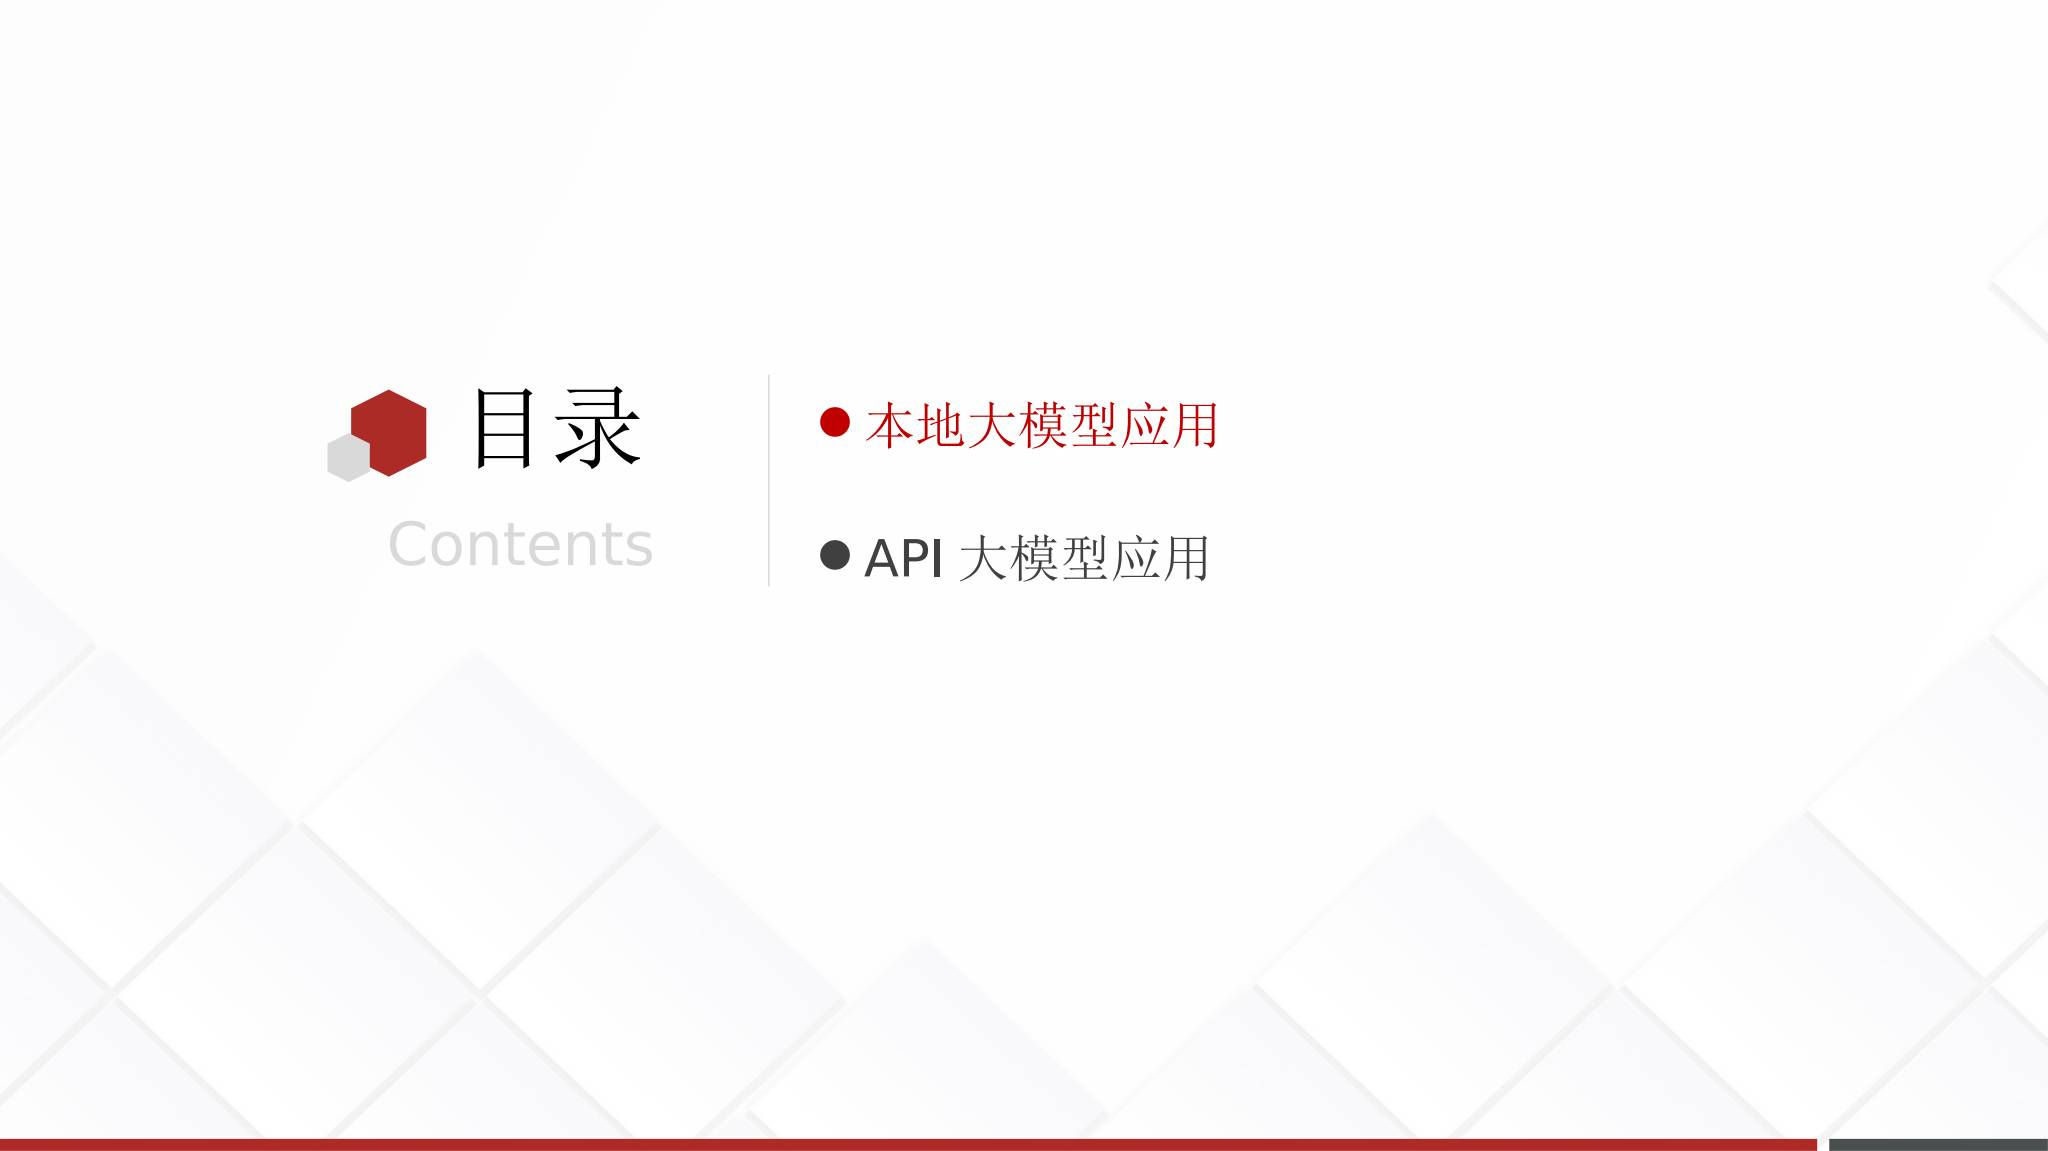


## 1. Dify 为什么要接入模型

Dify 负责应用编排，但聊天助手、工作流和 Agent 仍然需要一个大模型来理解用户输入、生成回答和参与决策。本章把模型来源分为两类：

| 路线 | 模型运行位置 | 主要特点 |
| --- | --- | --- |
| Ollama 本地模型 | 自己的电脑或局域网机器 | 模型文件和推理服务由本地环境管理 |
| API 大模型 | 云端模型服务 | 通过接口远程调用，不需要自己部署模型 |

选择路线时，先看电脑资源、网络条件和数据要求。课程先演示本地路线，再演示 API 路线。


## 2. 本地模型接入的完整流程

课件将本地接入拆成五步：

1. 安装 Ollama。
2. 下载一个模型。
3. 在 Ollama 中运行模型。
4. 在 Dify 中配置 Ollama 供应商。
5. 在 Dify 中测试模型。

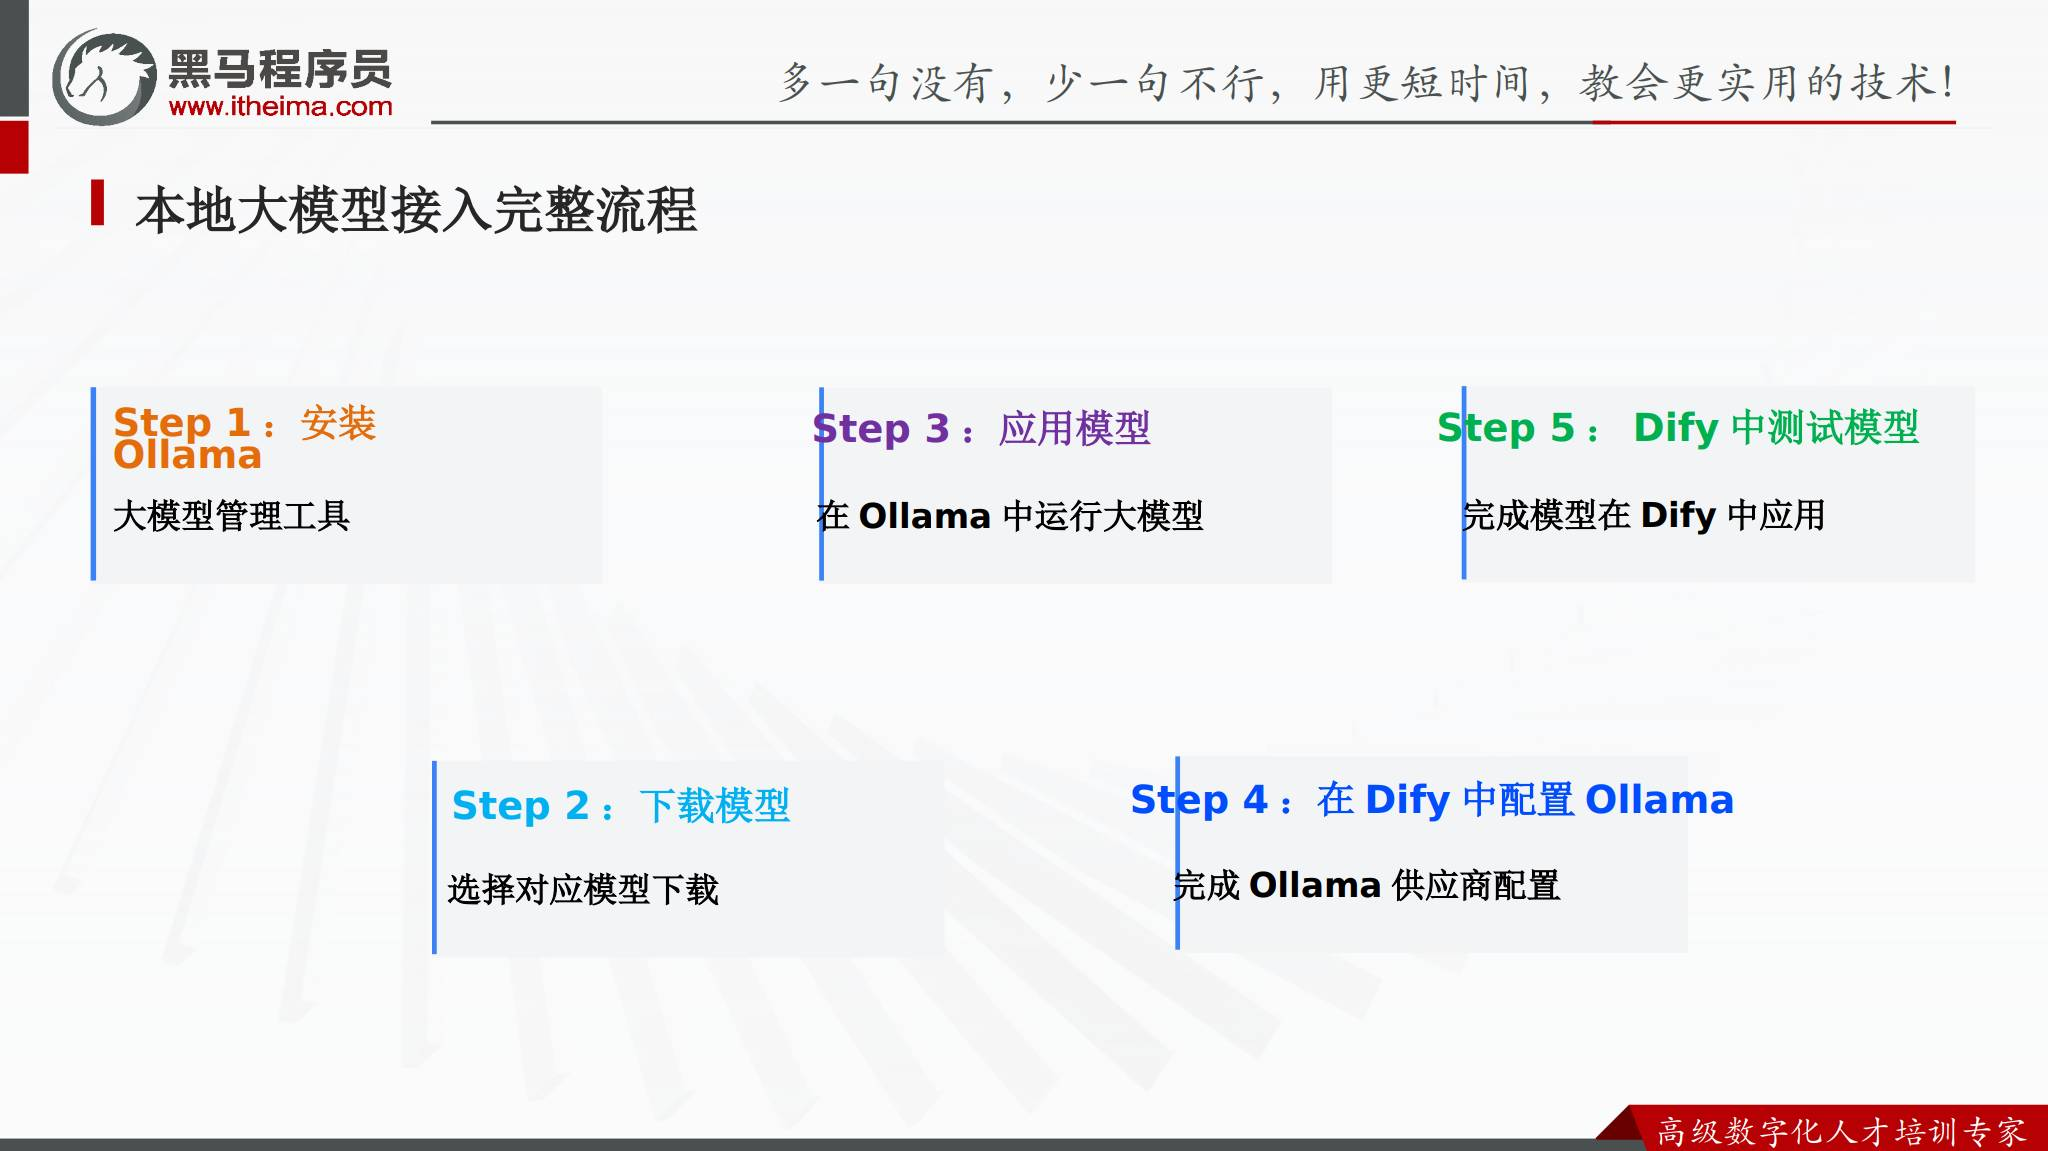

这条路线中，Ollama 负责模型的下载、管理和运行，Dify 通过 Ollama 提供的服务地址调用模型。


## 3. 第一步：安装 Ollama

Ollama 是一个开源的本地大模型运行框架，用于在本地部署、管理和运行开源 LLM 模型。课程给出的下载地址是 [https://ollama.com/download](https://ollama.com/download)，支持 macOS、Linux 和 Windows。

安装前需要确认：

- 当前系统与安装包匹配。
- 本地磁盘有足够空间保存模型文件。
- 电脑的内存和显存能够承载准备运行的模型。

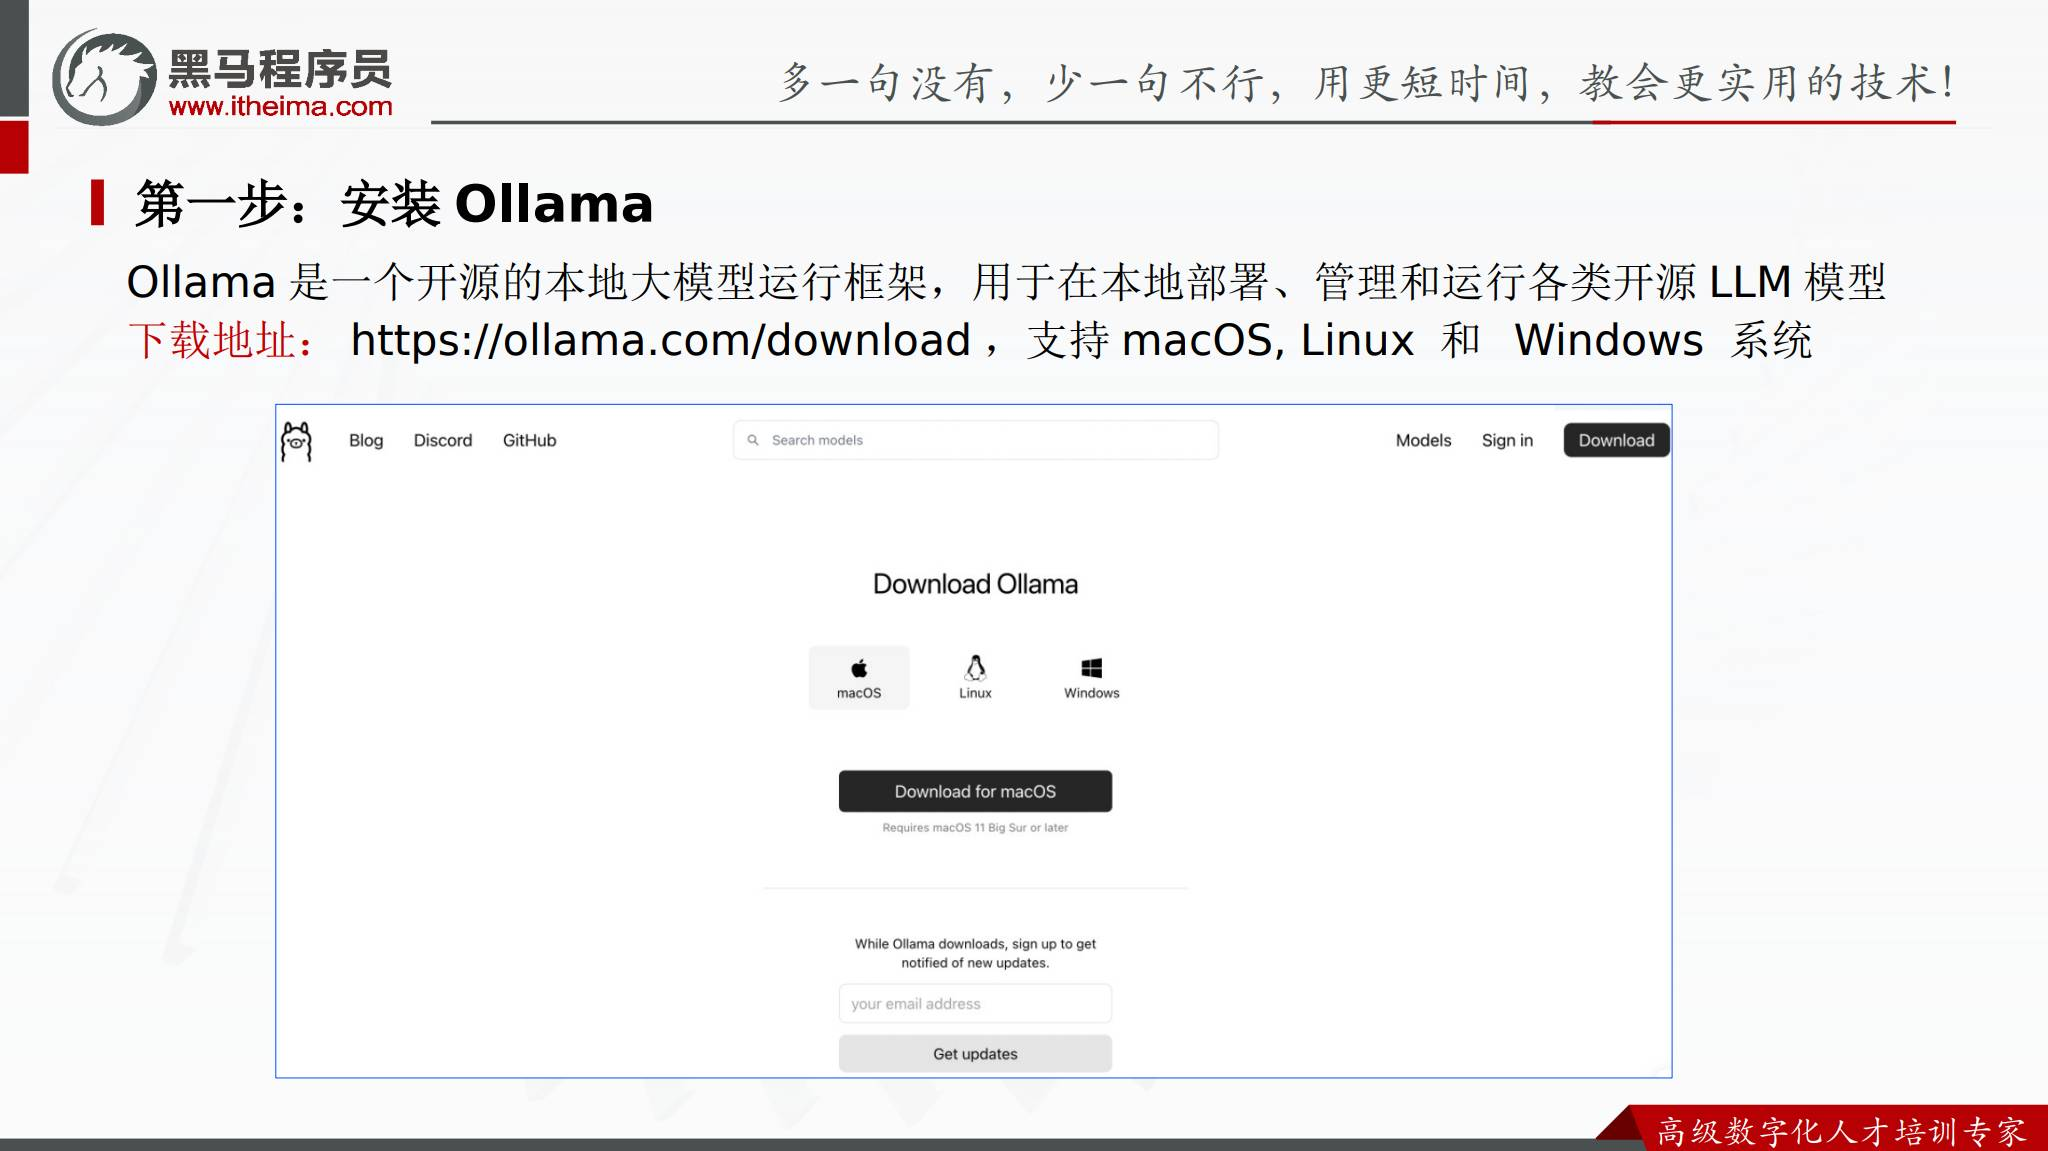


## 4. 第二步：下载模型

打开 Ollama 聊天页面，在 `Find model` 中搜索需要的模型。课程建议初学时先选择小模型，示例模型是 `qwen2.5:1.5b`。

```text
Find model: qwen2.5:1.5b
```

模型越大，对内存、显存和磁盘空间的要求通常越高。先用小模型跑通完整链路，再根据任务质量和硬件条件调整模型。

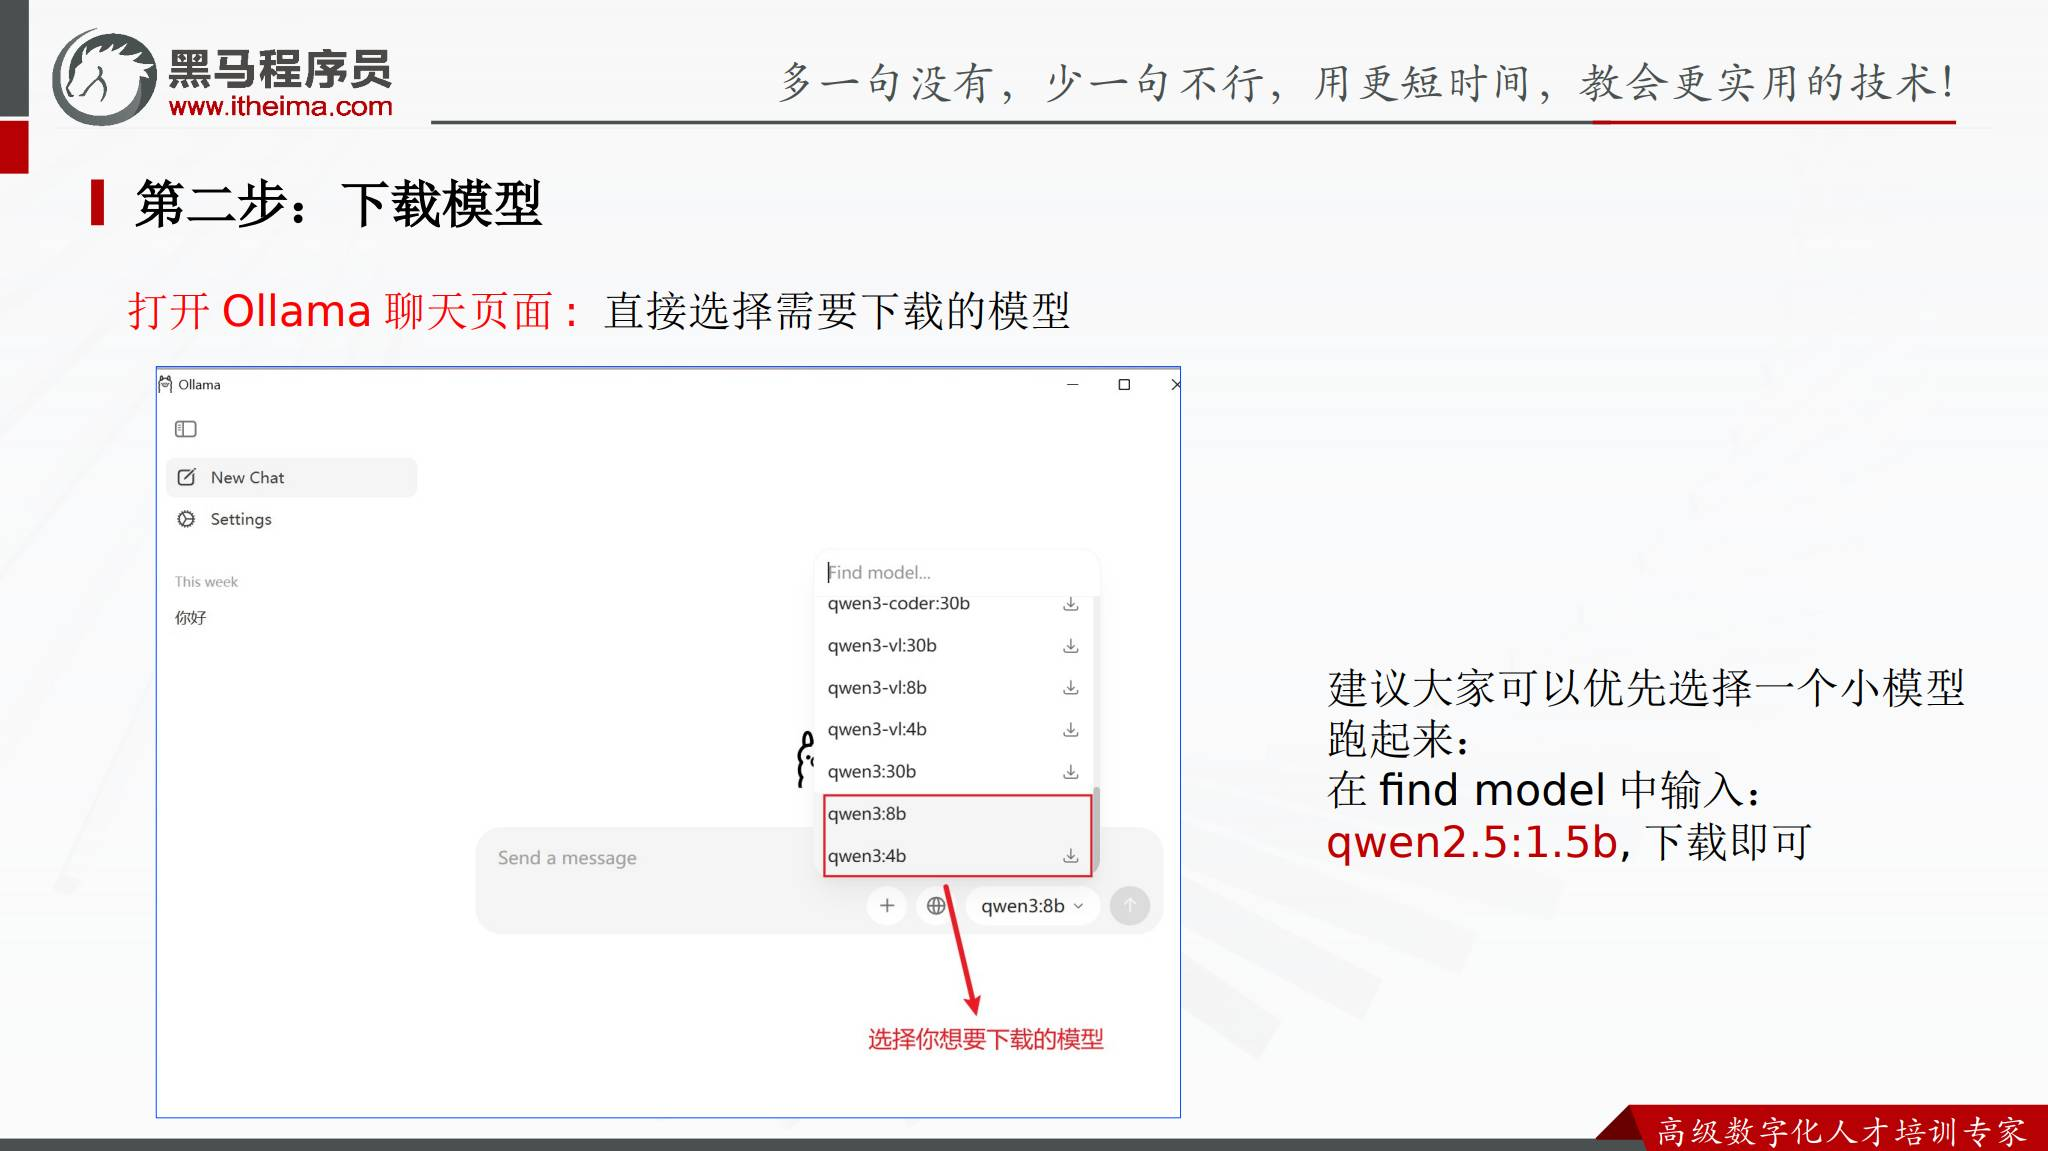


## 5. 第三步：在 Ollama 中运行模型

模型下载完成后，可以在 Ollama 的对话页面中选择模型并输入消息，确认模型能够正常回答。这个步骤先验证模型本身可用，后面再把同一个模型接到 Dify。

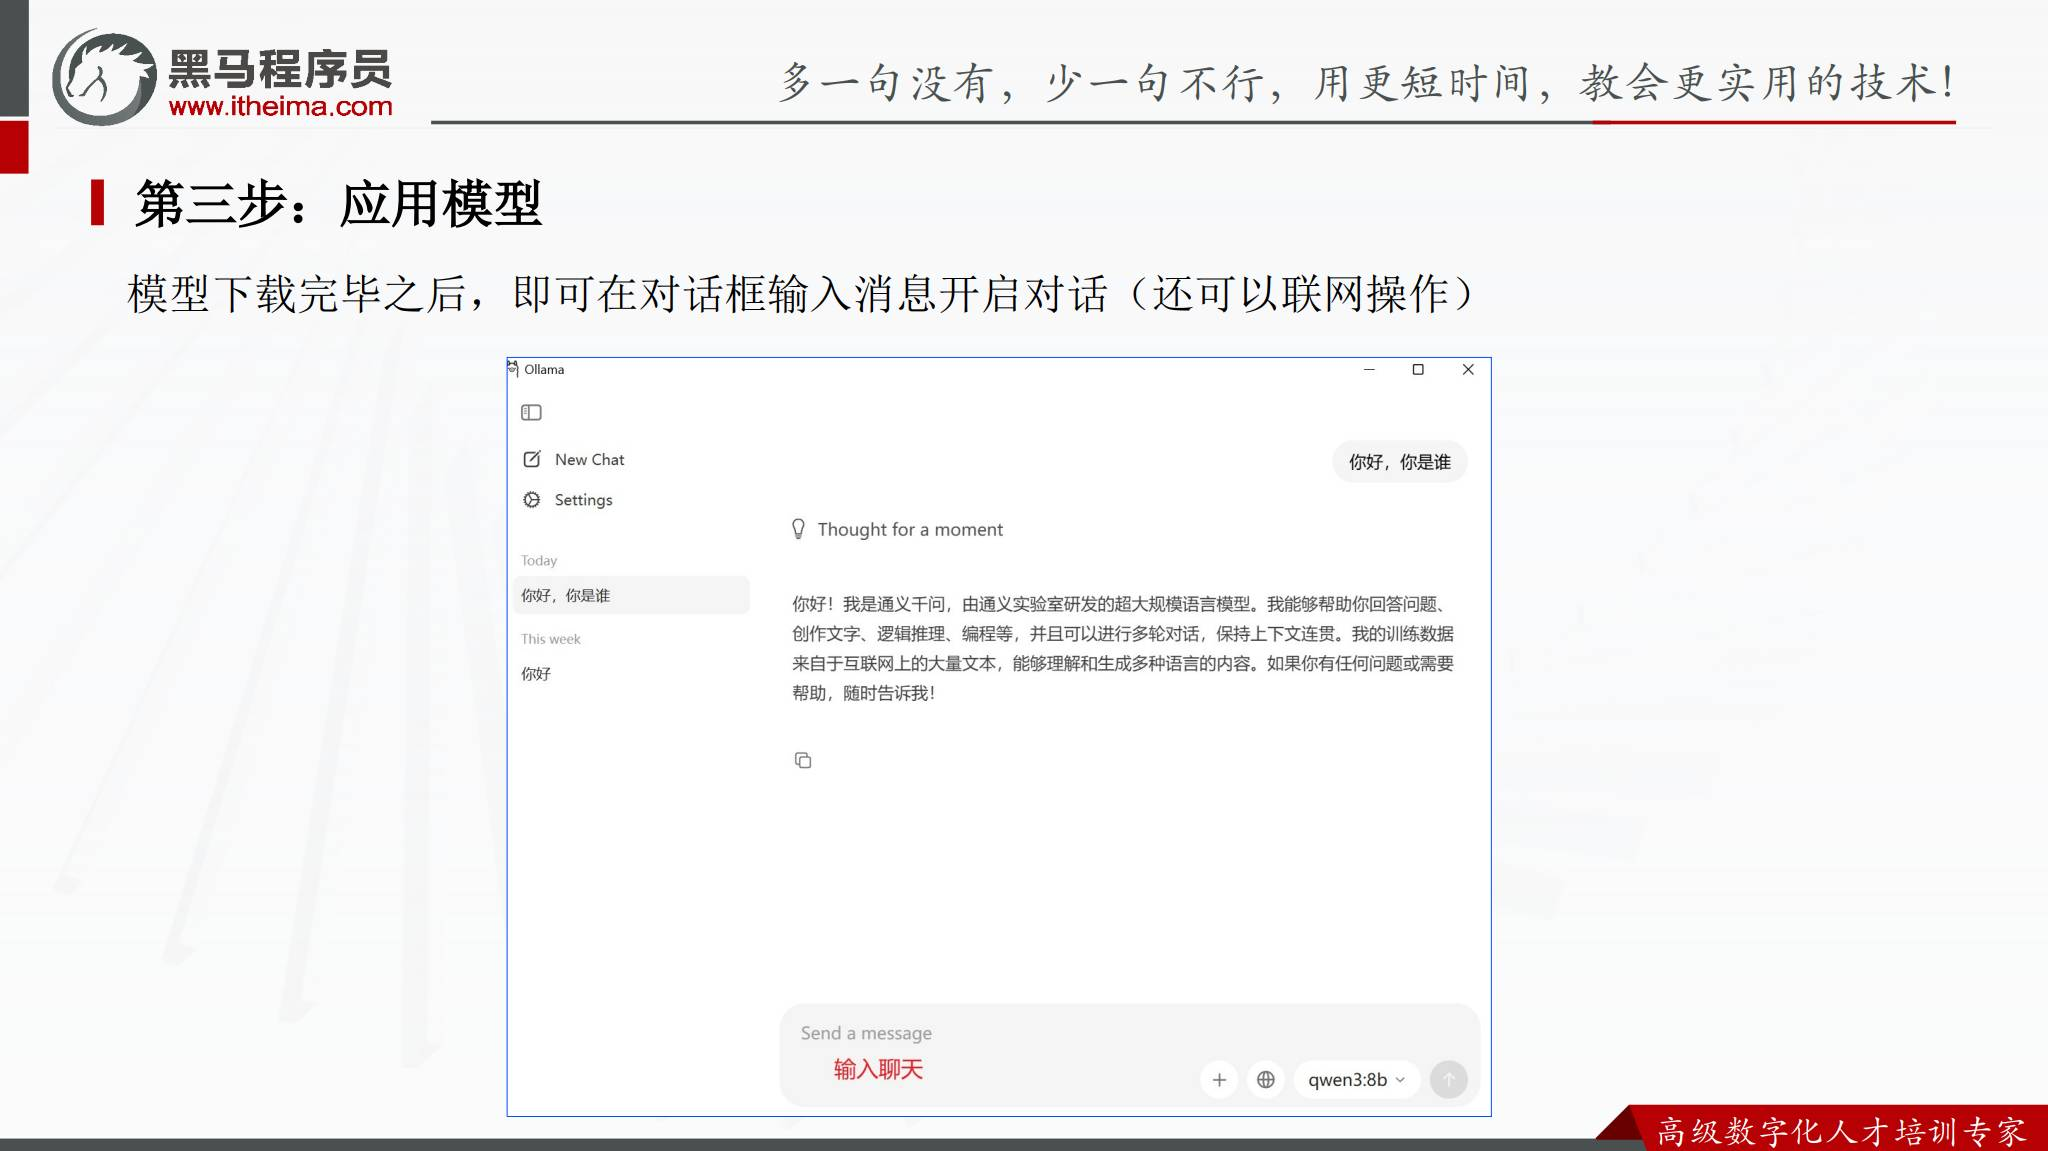


## 6. 第四步：在 Dify 中安装 Ollama 供应商

登录 Dify，在模型供应商或市场中搜索 `Ollama` 并安装对应的供应商。安装完成后，在模型列表中找到 Ollama，继续添加本地模型。

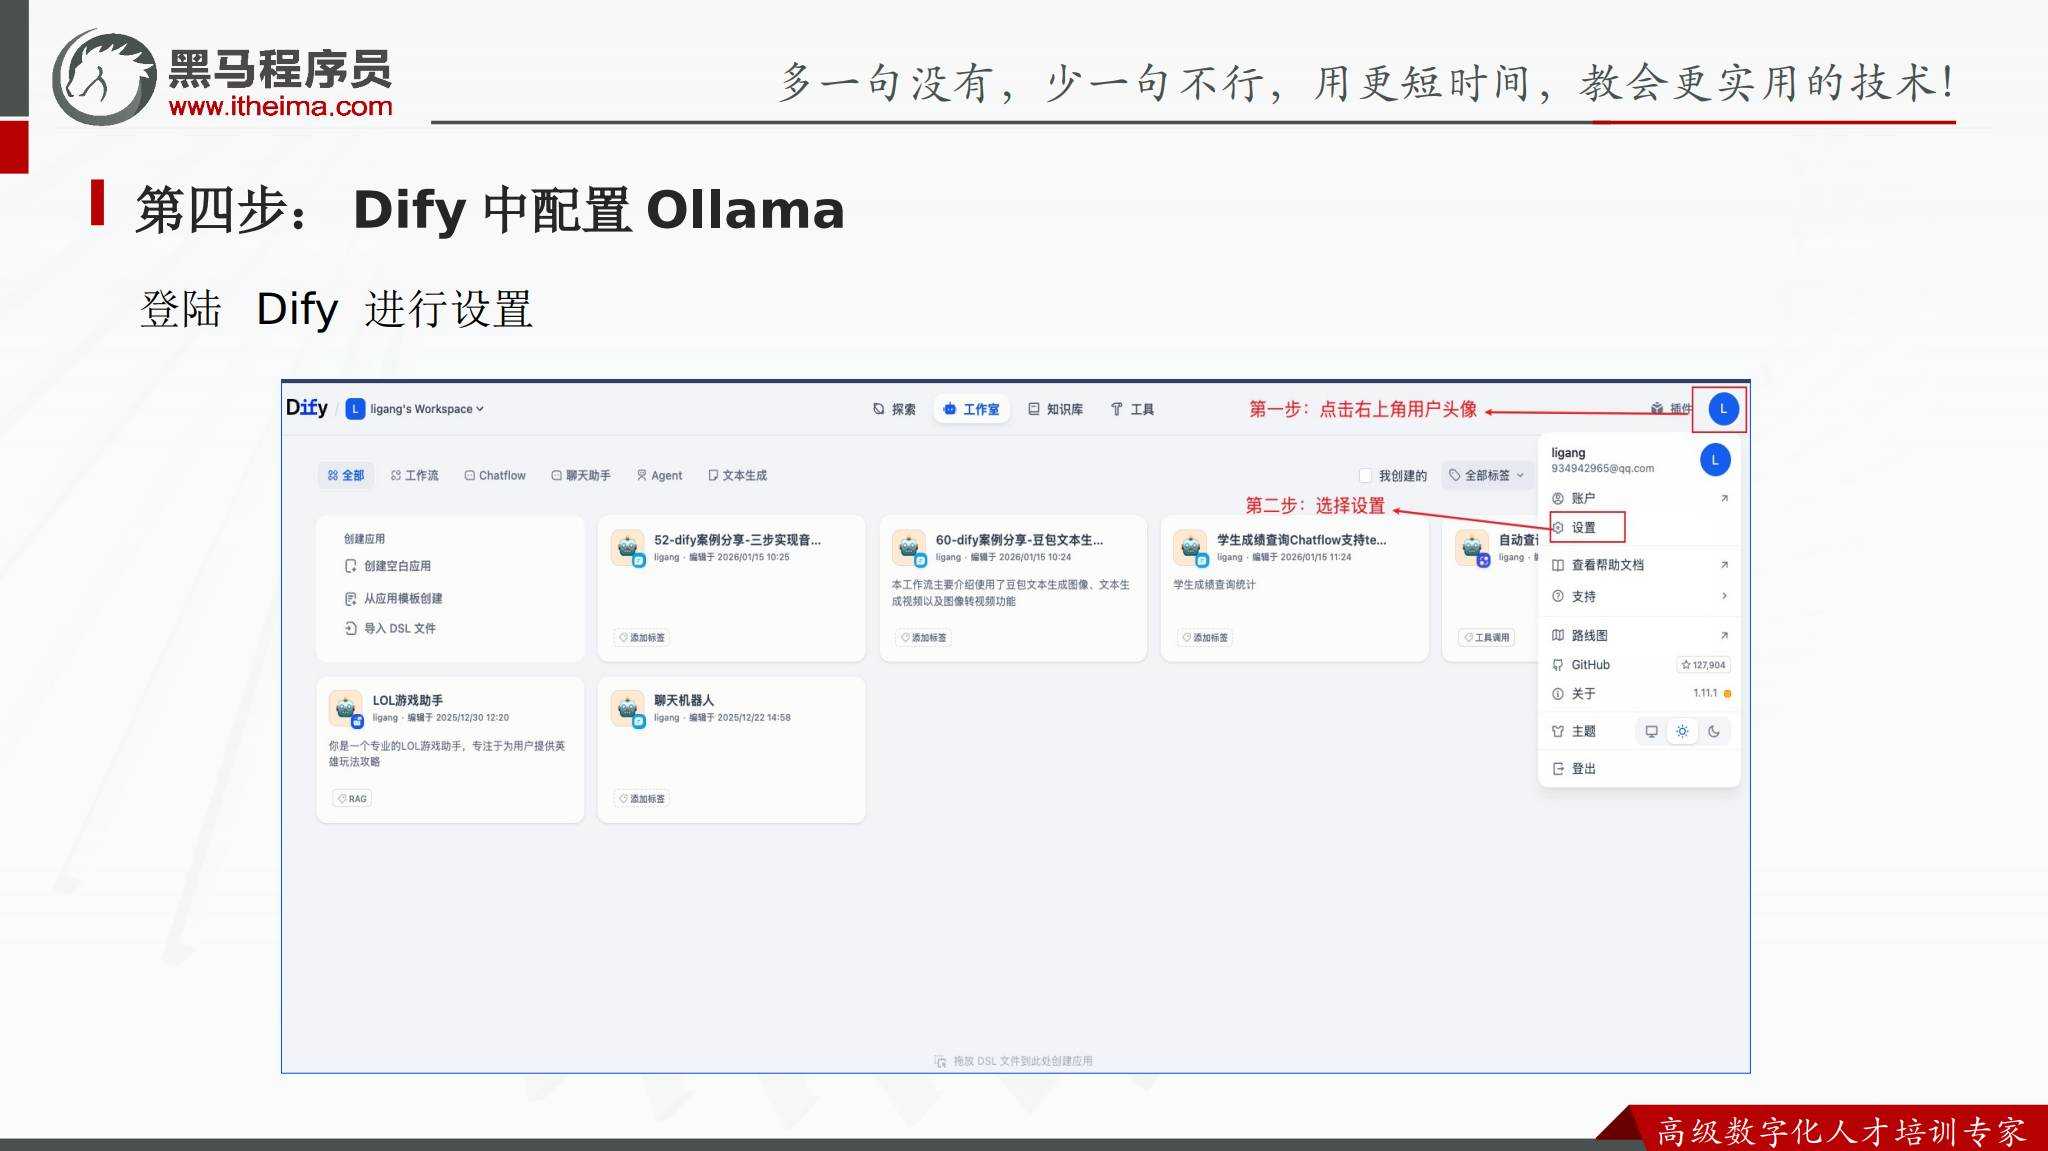

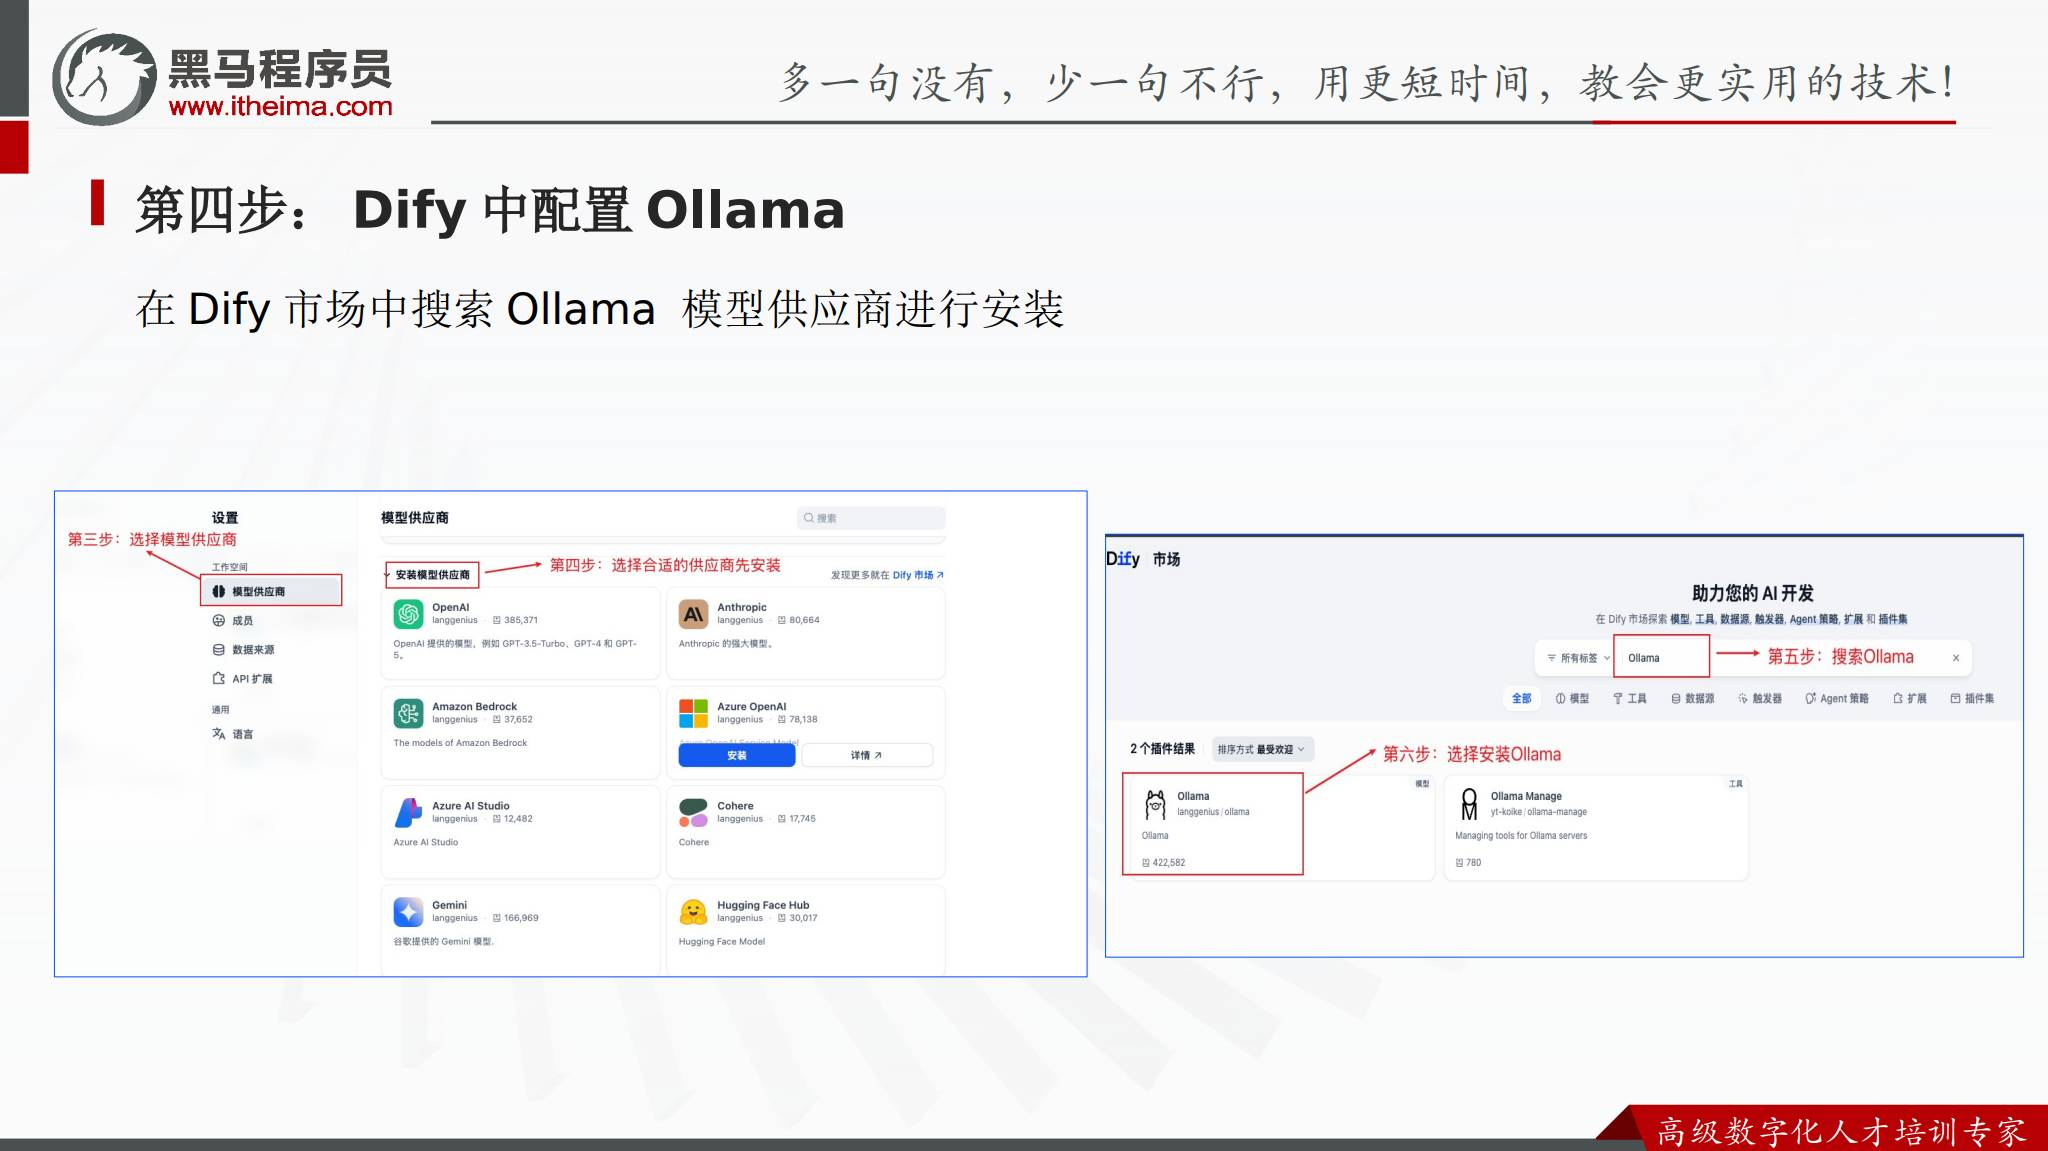


## 7. Ollama 的基础 URL 怎么填写

课件区分了 Dify 与 Ollama 是否运行在同一台机器上：

| 部署关系 | 基础 URL 示例 | 说明 |
| --- | --- | --- |
| Docker 在同一台机器部署 Dify 和 Ollama | `http://host.docker.internal:11434` | 让 Dify 容器访问宿主机上的 Ollama 服务 |
| Dify 与 Ollama 在不同机器 | `http://192.168.x.x:11434` | 把 `192.168.x.x` 替换为 Ollama 所在机器的实际 IP |

端口 `11434` 是课件示例中的 Ollama 服务端口。填写地址时，要结合实际部署方式确认 Dify 容器能够访问该地址。

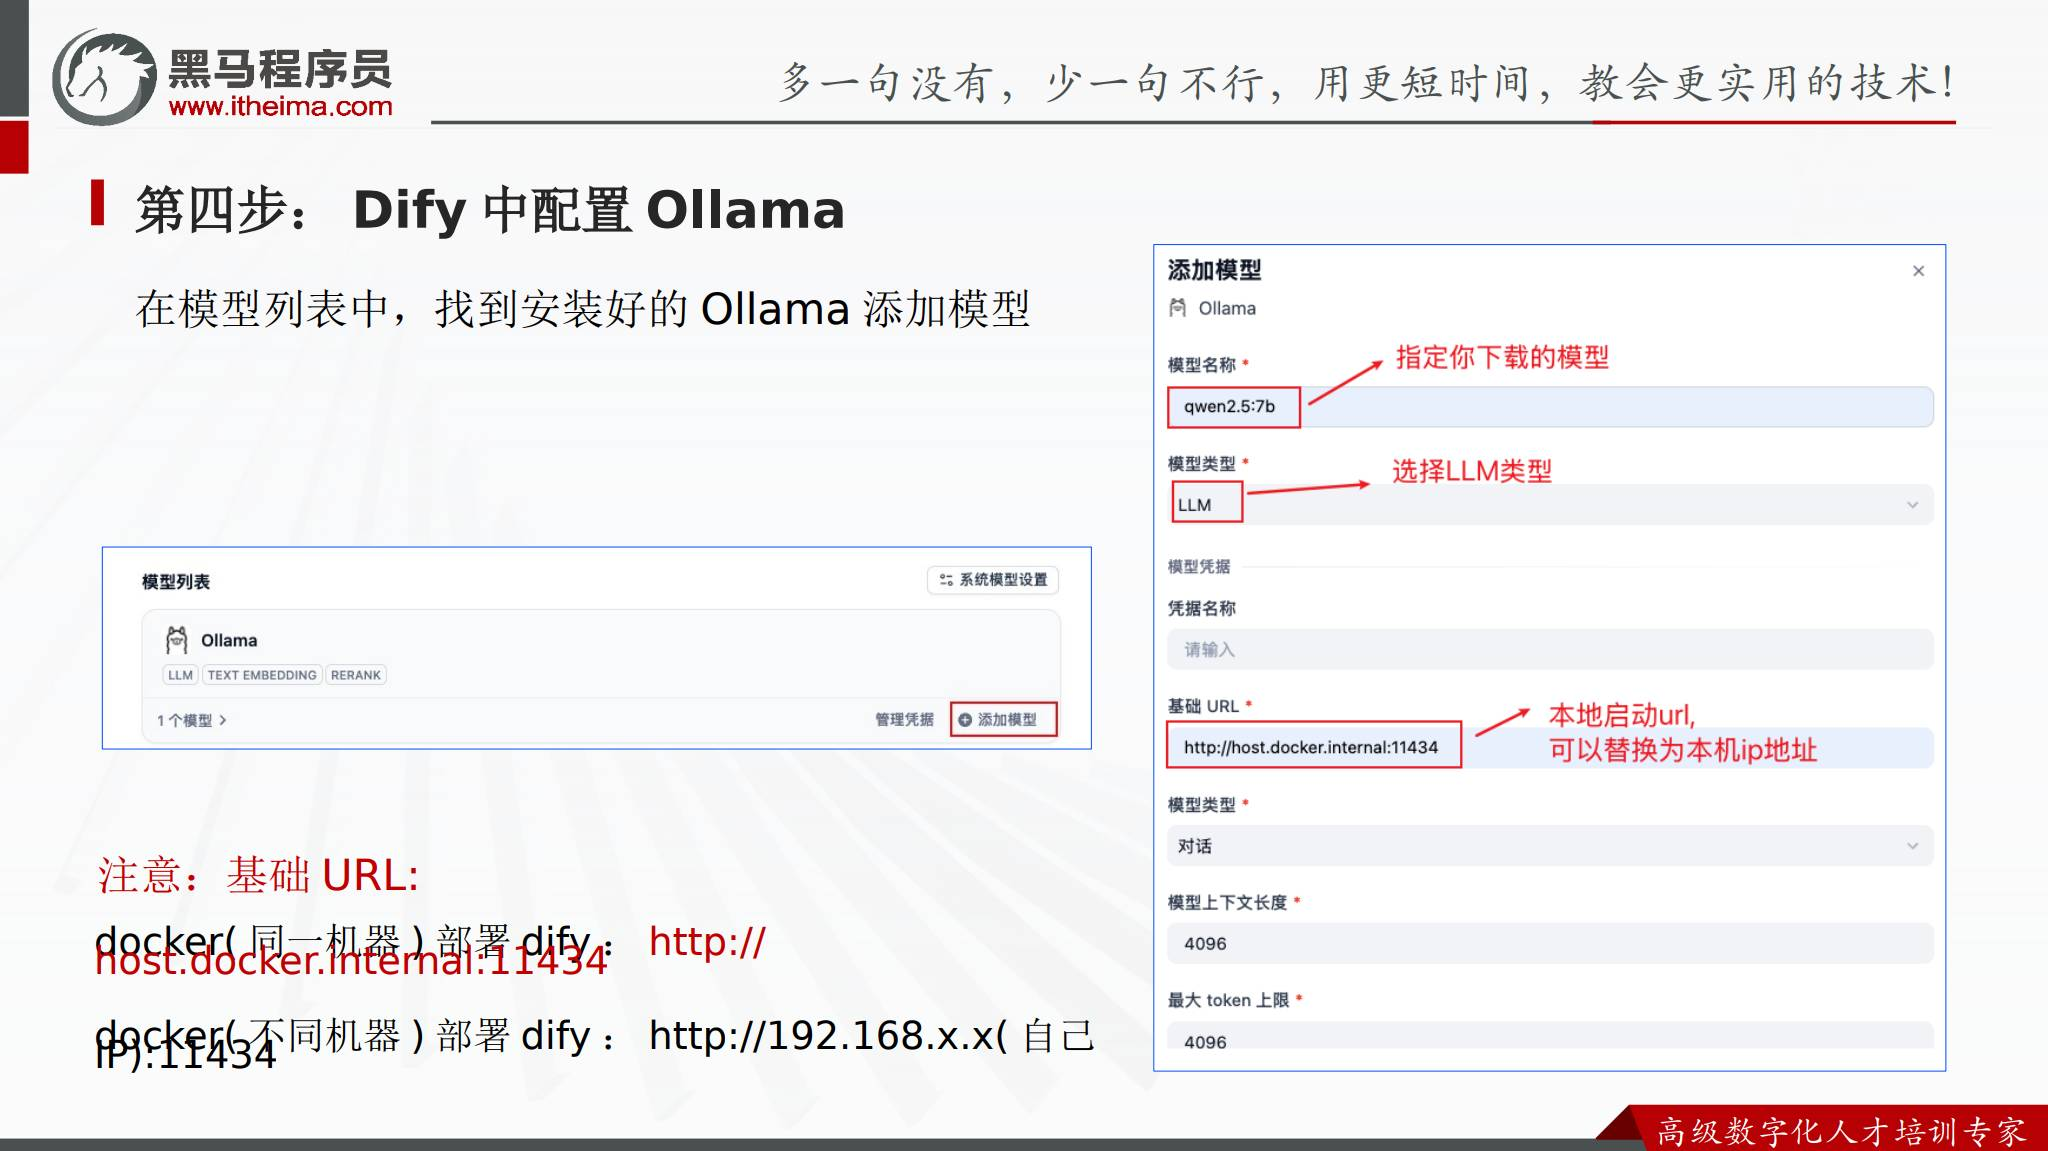


## 8. 第五步：在 Dify 中测试本地模型

供应商和模型配置完成后，在 Dify 的应用中选择刚添加的 Ollama 模型，发送一条测试消息。测试重点是：

1. Dify 能够找到模型。
2. 请求能够从 Dify 发到 Ollama。
3. Ollama 能够返回模型结果。
4. Dify 能够把结果展示在应用中。

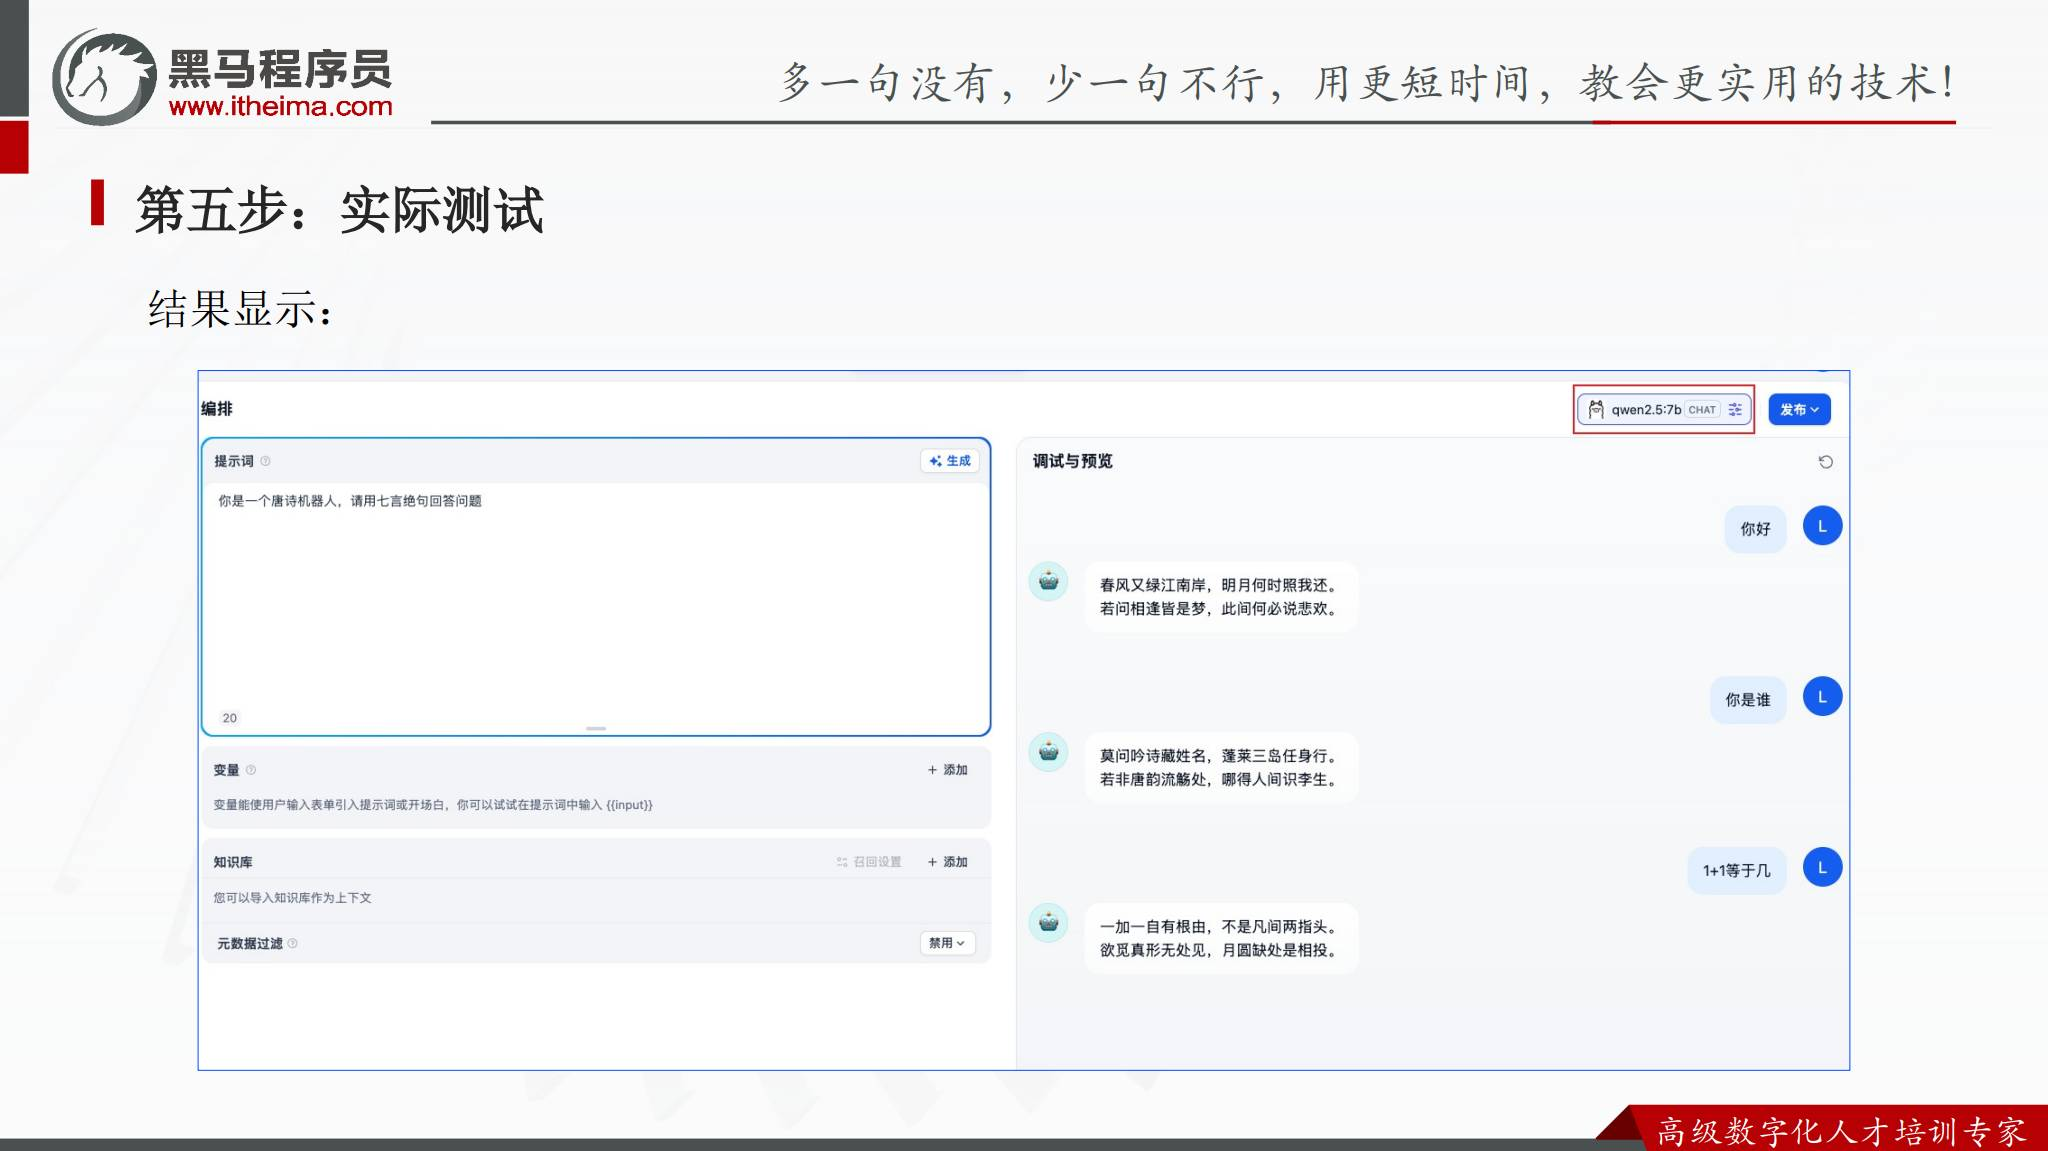

如果测试失败，按“模型是否下载完成、Ollama 是否正在运行、基础 URL 是否可访问、模型名称是否一致”的顺序检查。


## 9. 本地模型路线小结

Ollama 在本地模型路线中承担模型管理工具的角色。完整过程可以压缩为：

> 安装 Ollama，下载模型，运行模型，在 Dify 中配置 Ollama，最后测试模型。

这条路线适合学习模型接入流程，也适合需要把模型运行在本地环境中的场景。模型能力和响应速度会受到本机硬件、模型大小和运行配置影响。


## 10. API 大模型接入的完整流程

云端 API 路线同样分为五步：

1. 注册阿里云账号。
2. 登录百炼平台并完成实名认证。
3. 获取 API Key。
4. 在 Dify 中配置 API 模型供应商。
5. 在 Dify 中测试模型。

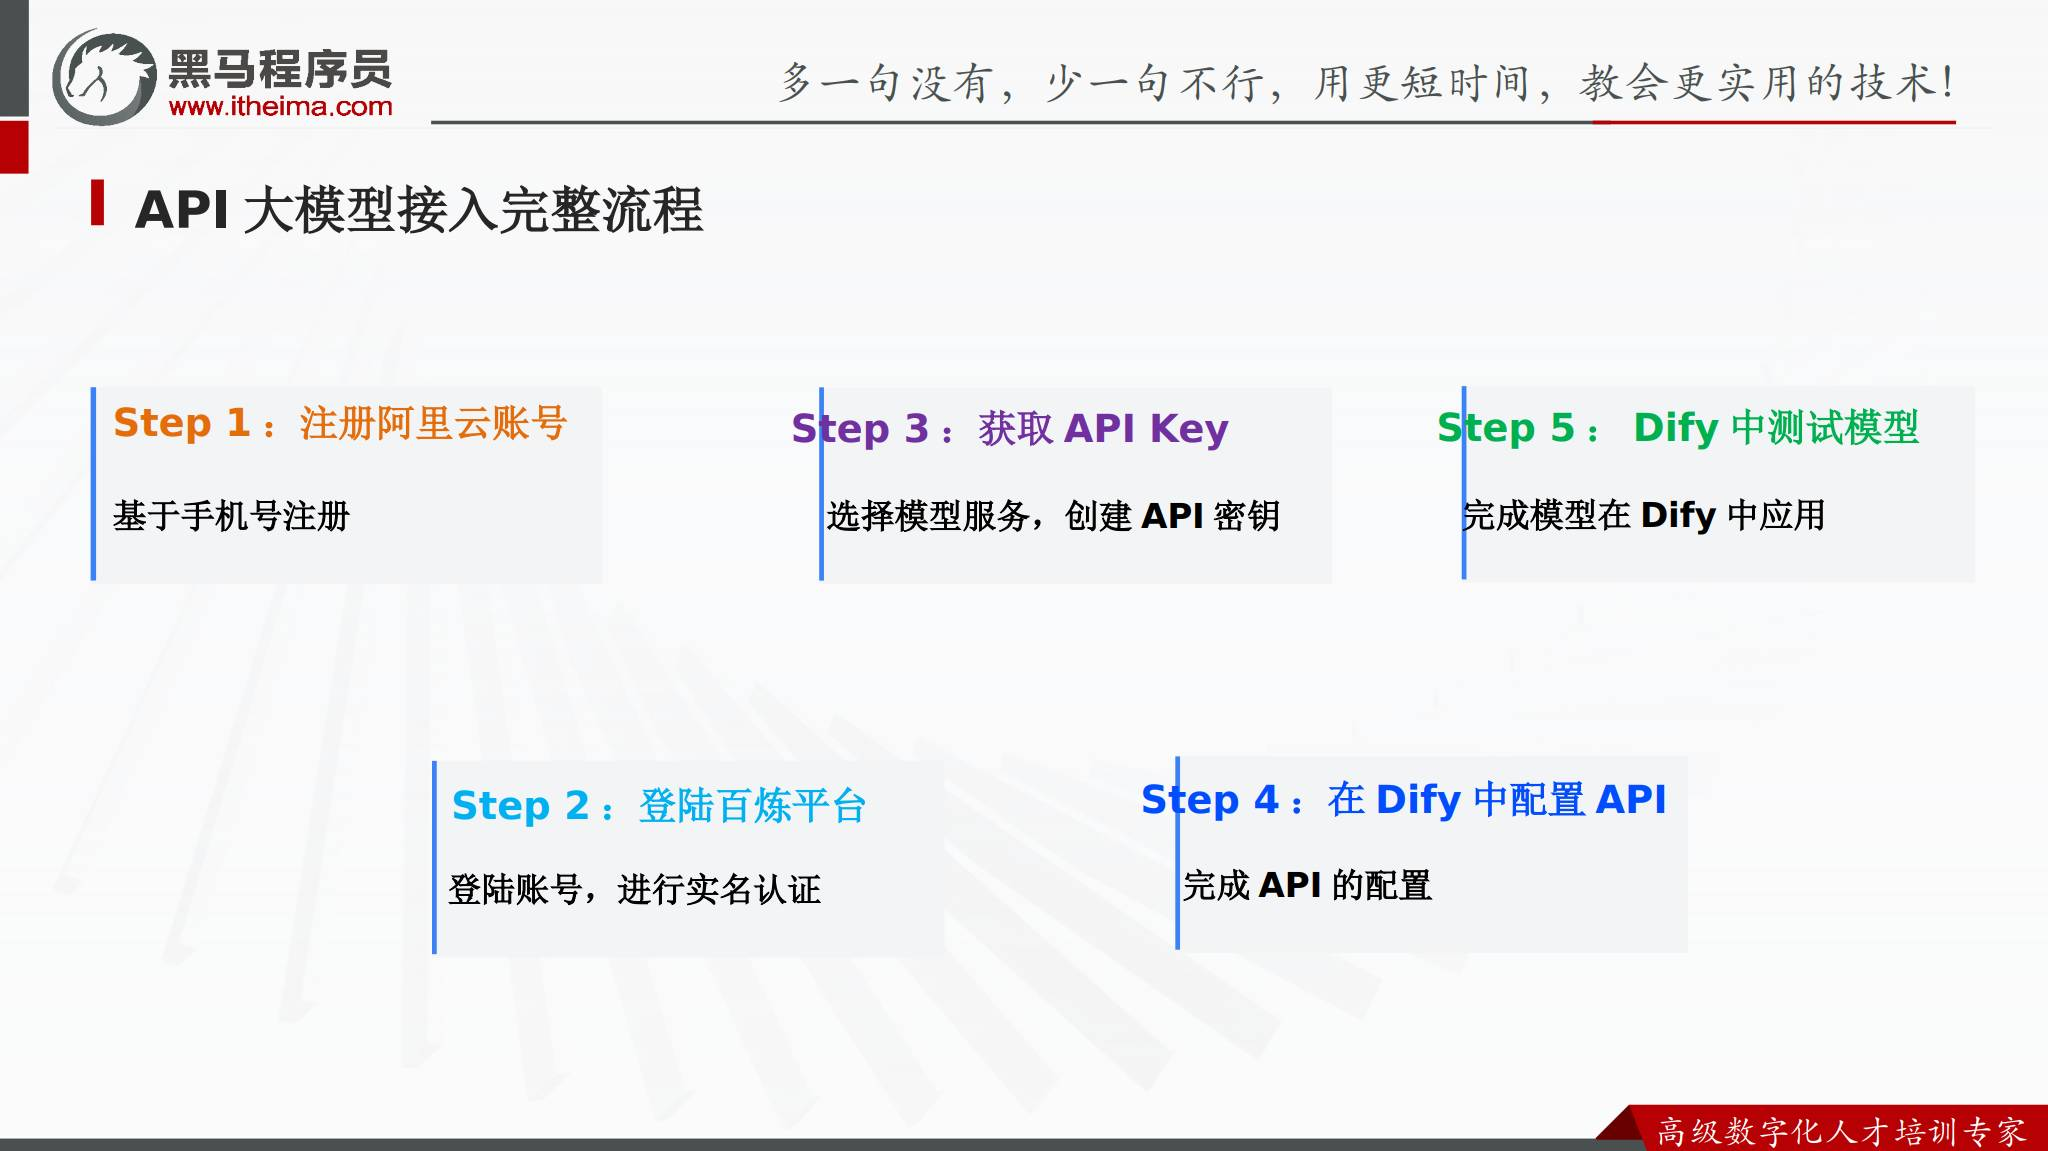

这条路线不需要在本地保存和运行模型，Dify 通过 API 请求云端模型服务。


## 11. 第一步和第二步：注册并登录百炼

课程使用阿里云百炼作为 API 模型示例，入口地址为 [https://www.aliyun.com/product/bailian](https://www.aliyun.com/product/bailian)。操作顺序如下：

1. 使用手机号注册阿里云账号。
2. 登录百炼平台。
3. 按平台要求完成实名认证。
4. 根据实际使用情况查询账户余额，是否充值由使用者自行决定。

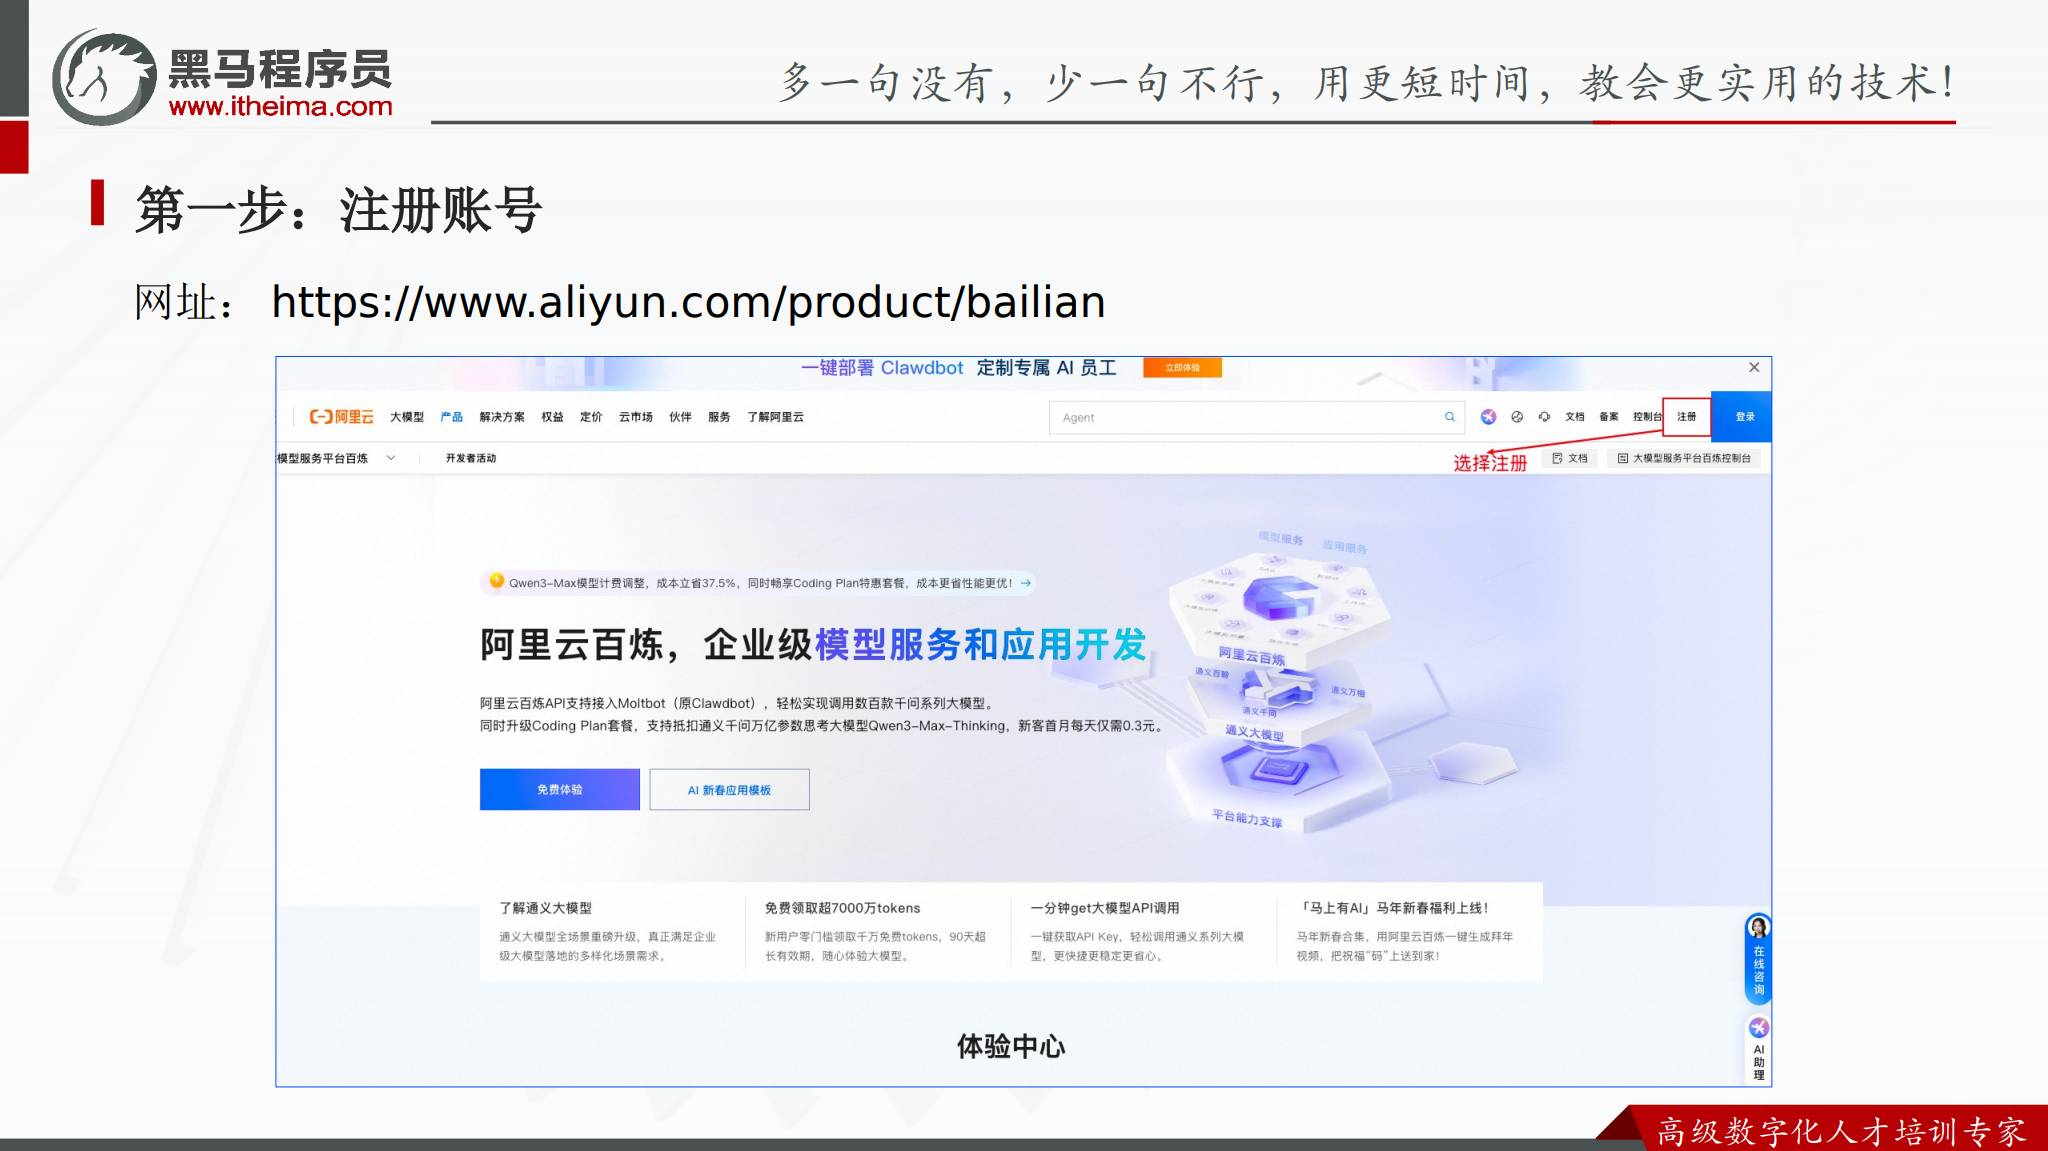

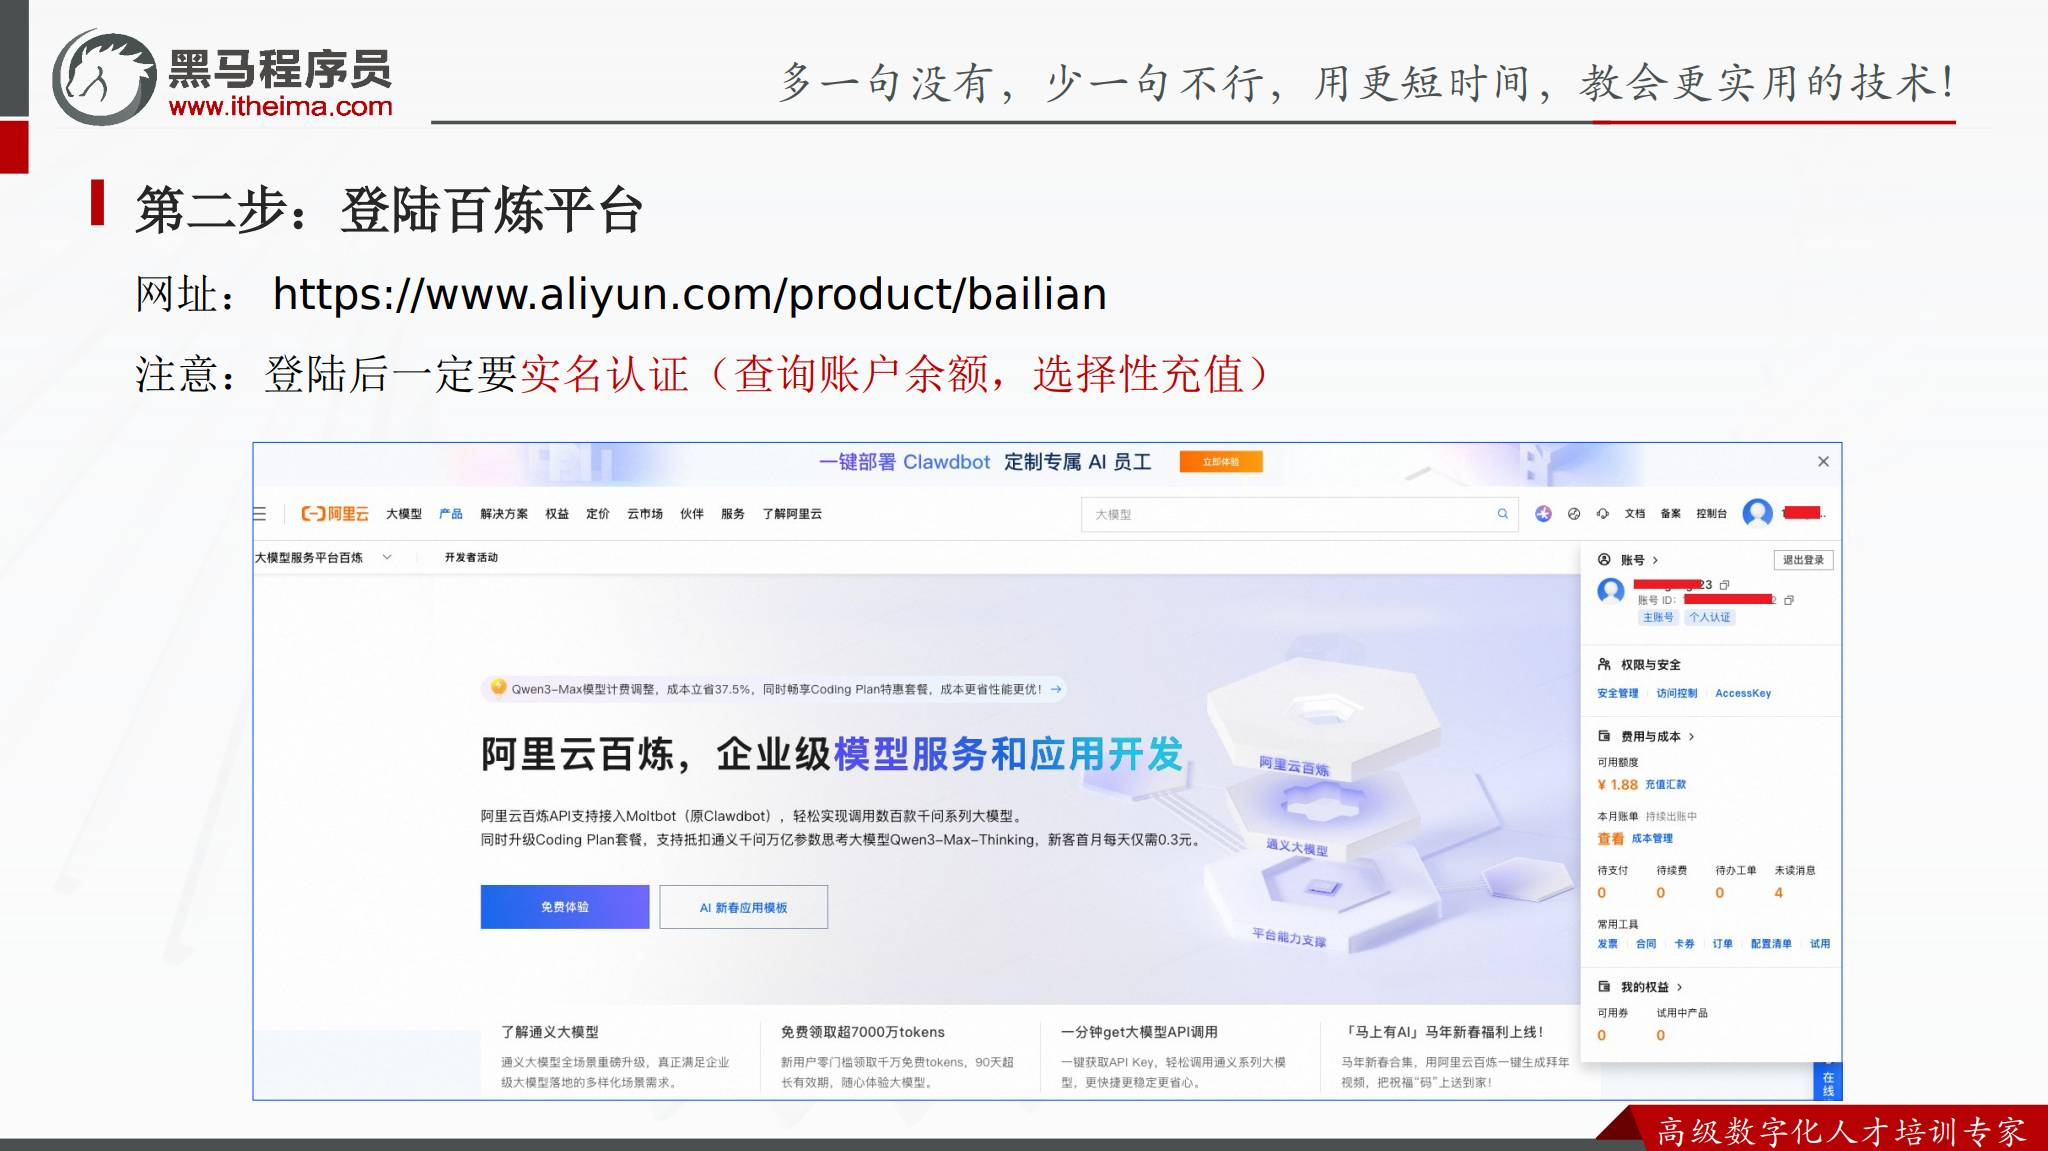


## 12. 第三步：获取 API Key

课程给出的 API Key 页面地址是：

<https://bailian.console.aliyun.com/cn-beijing/?tab=model#/api-key>

在模型服务控制台中创建或获取 API Key，供 Dify 的模型供应商配置使用。

API Key 属于访问凭证，不能写入公开笔记、代码仓库或截图中。配置时使用自己的密钥，示例中不要填写真实密钥。

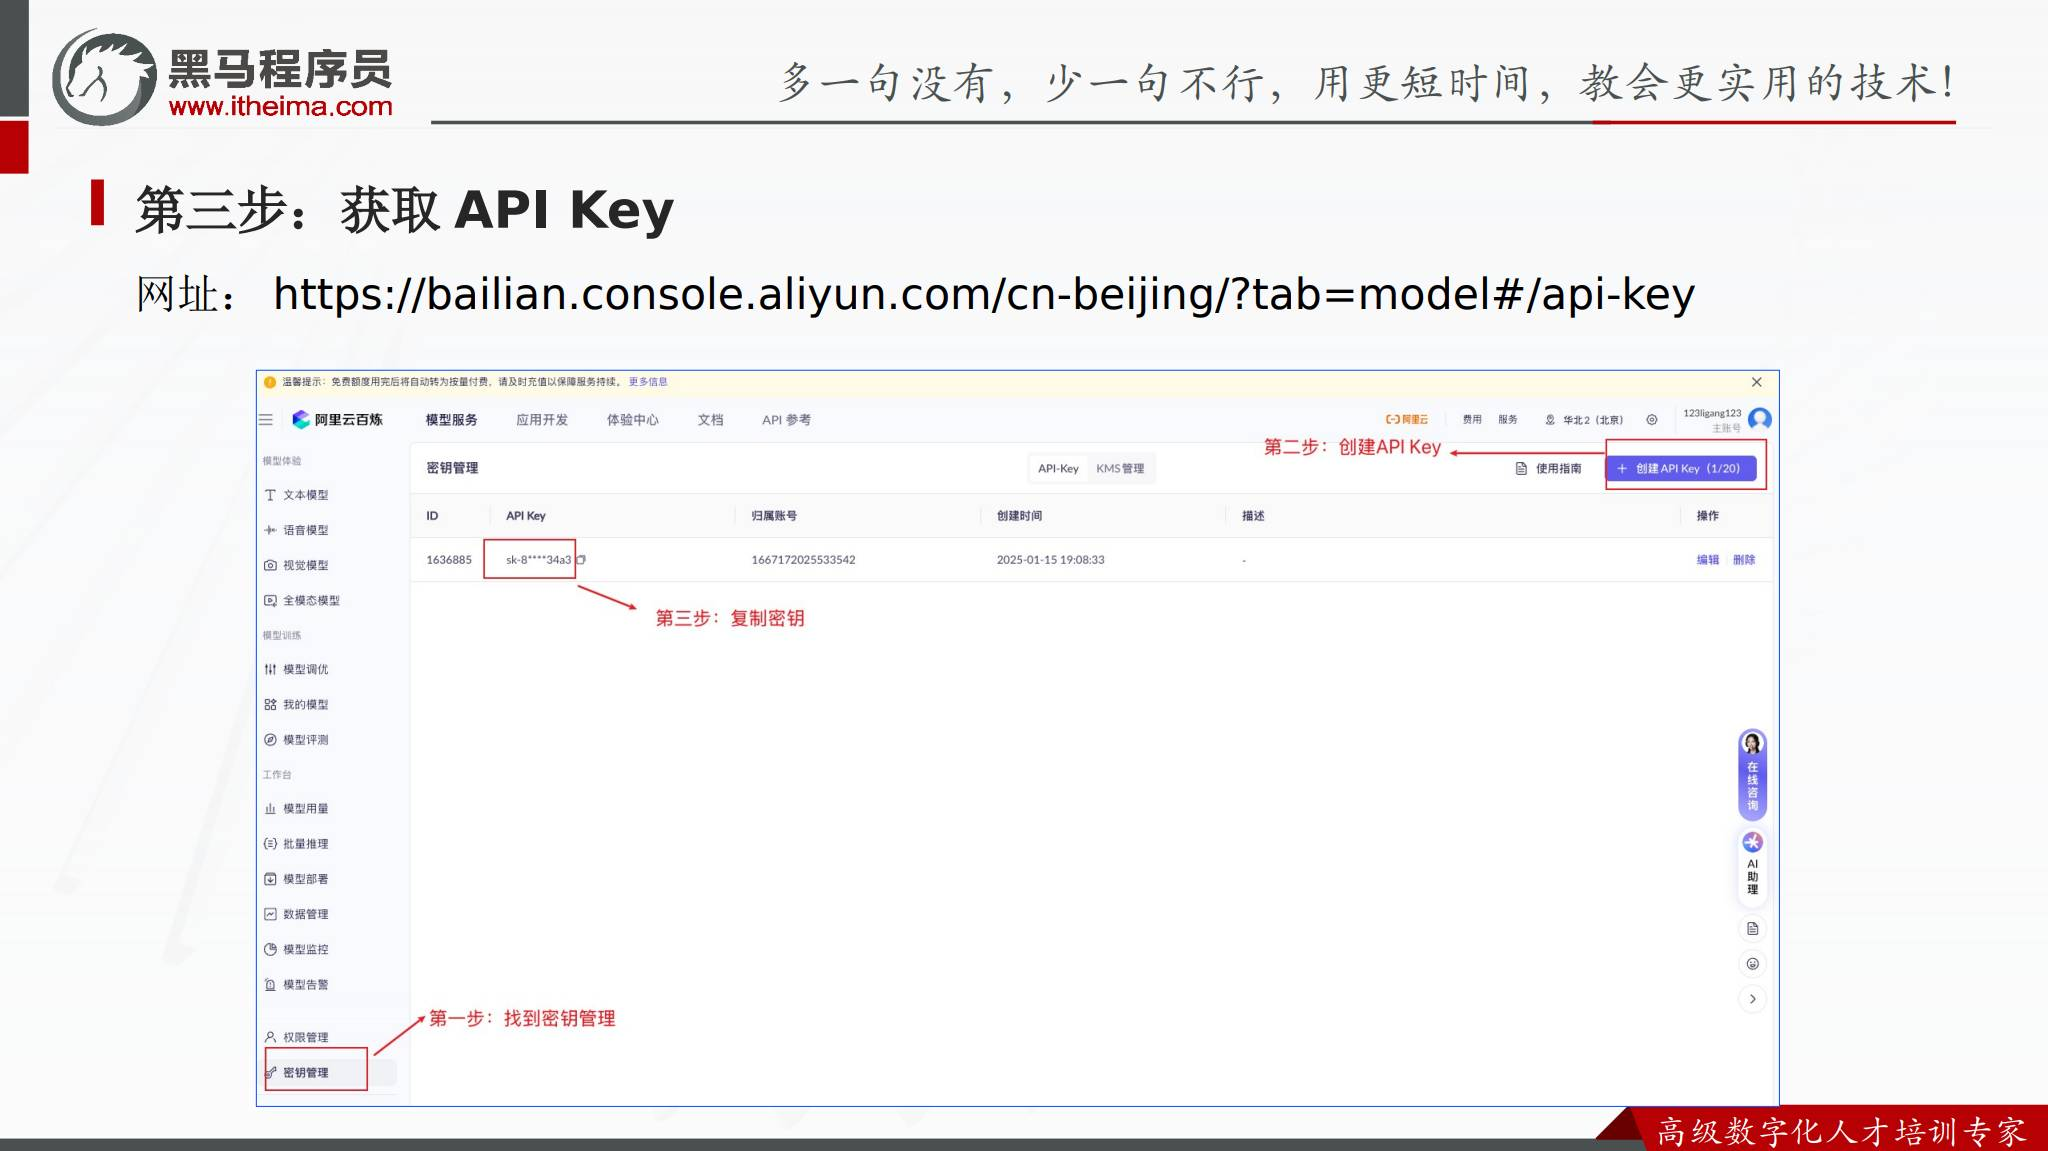


## 13. 第四步：在 Dify 中配置 API 模型

登录 Dify，在模型市场中搜索并安装通义千问模型供应商。安装完成后，在模型列表中找到通义千问，填写 API Key 并完成模型设置。

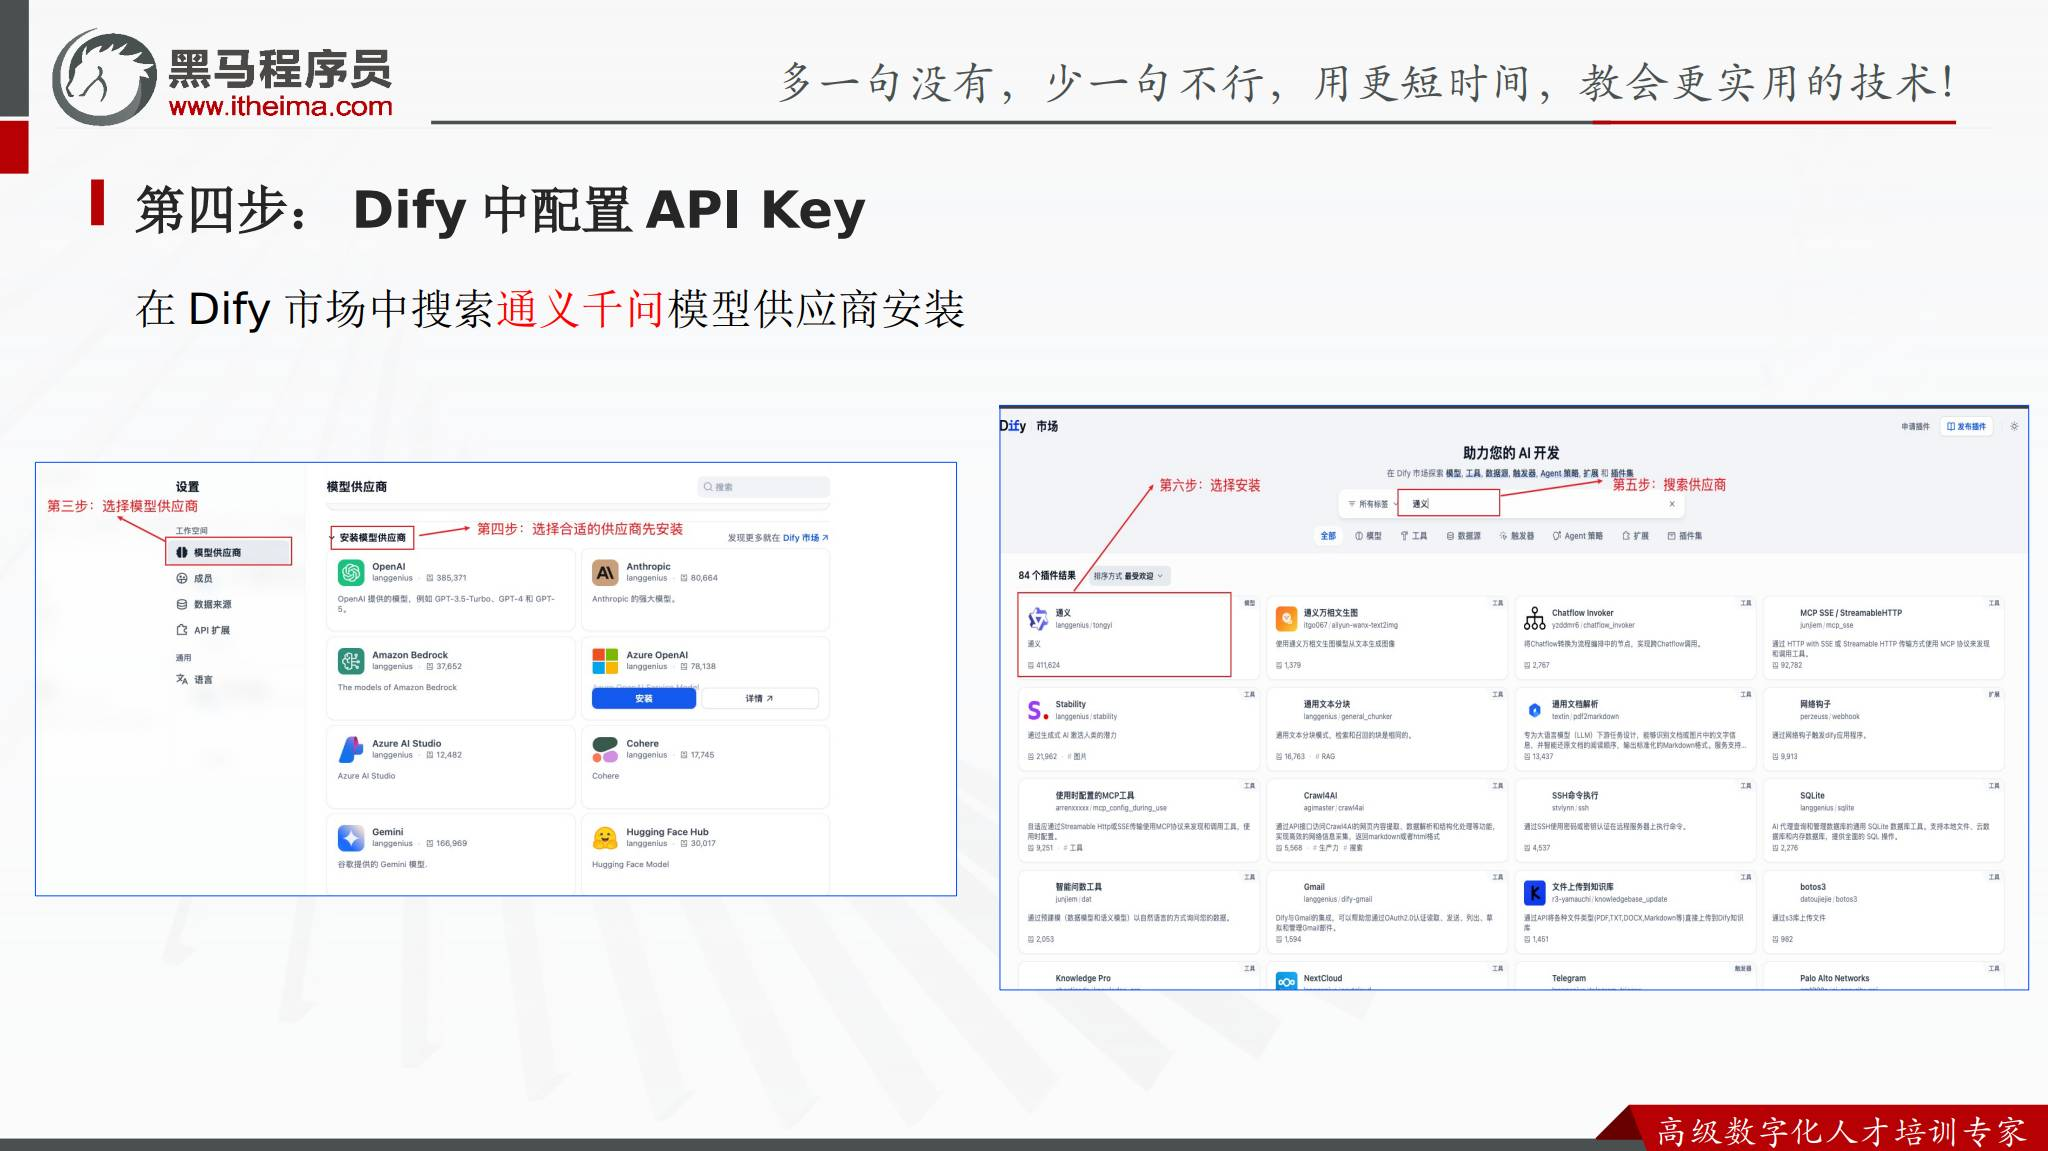

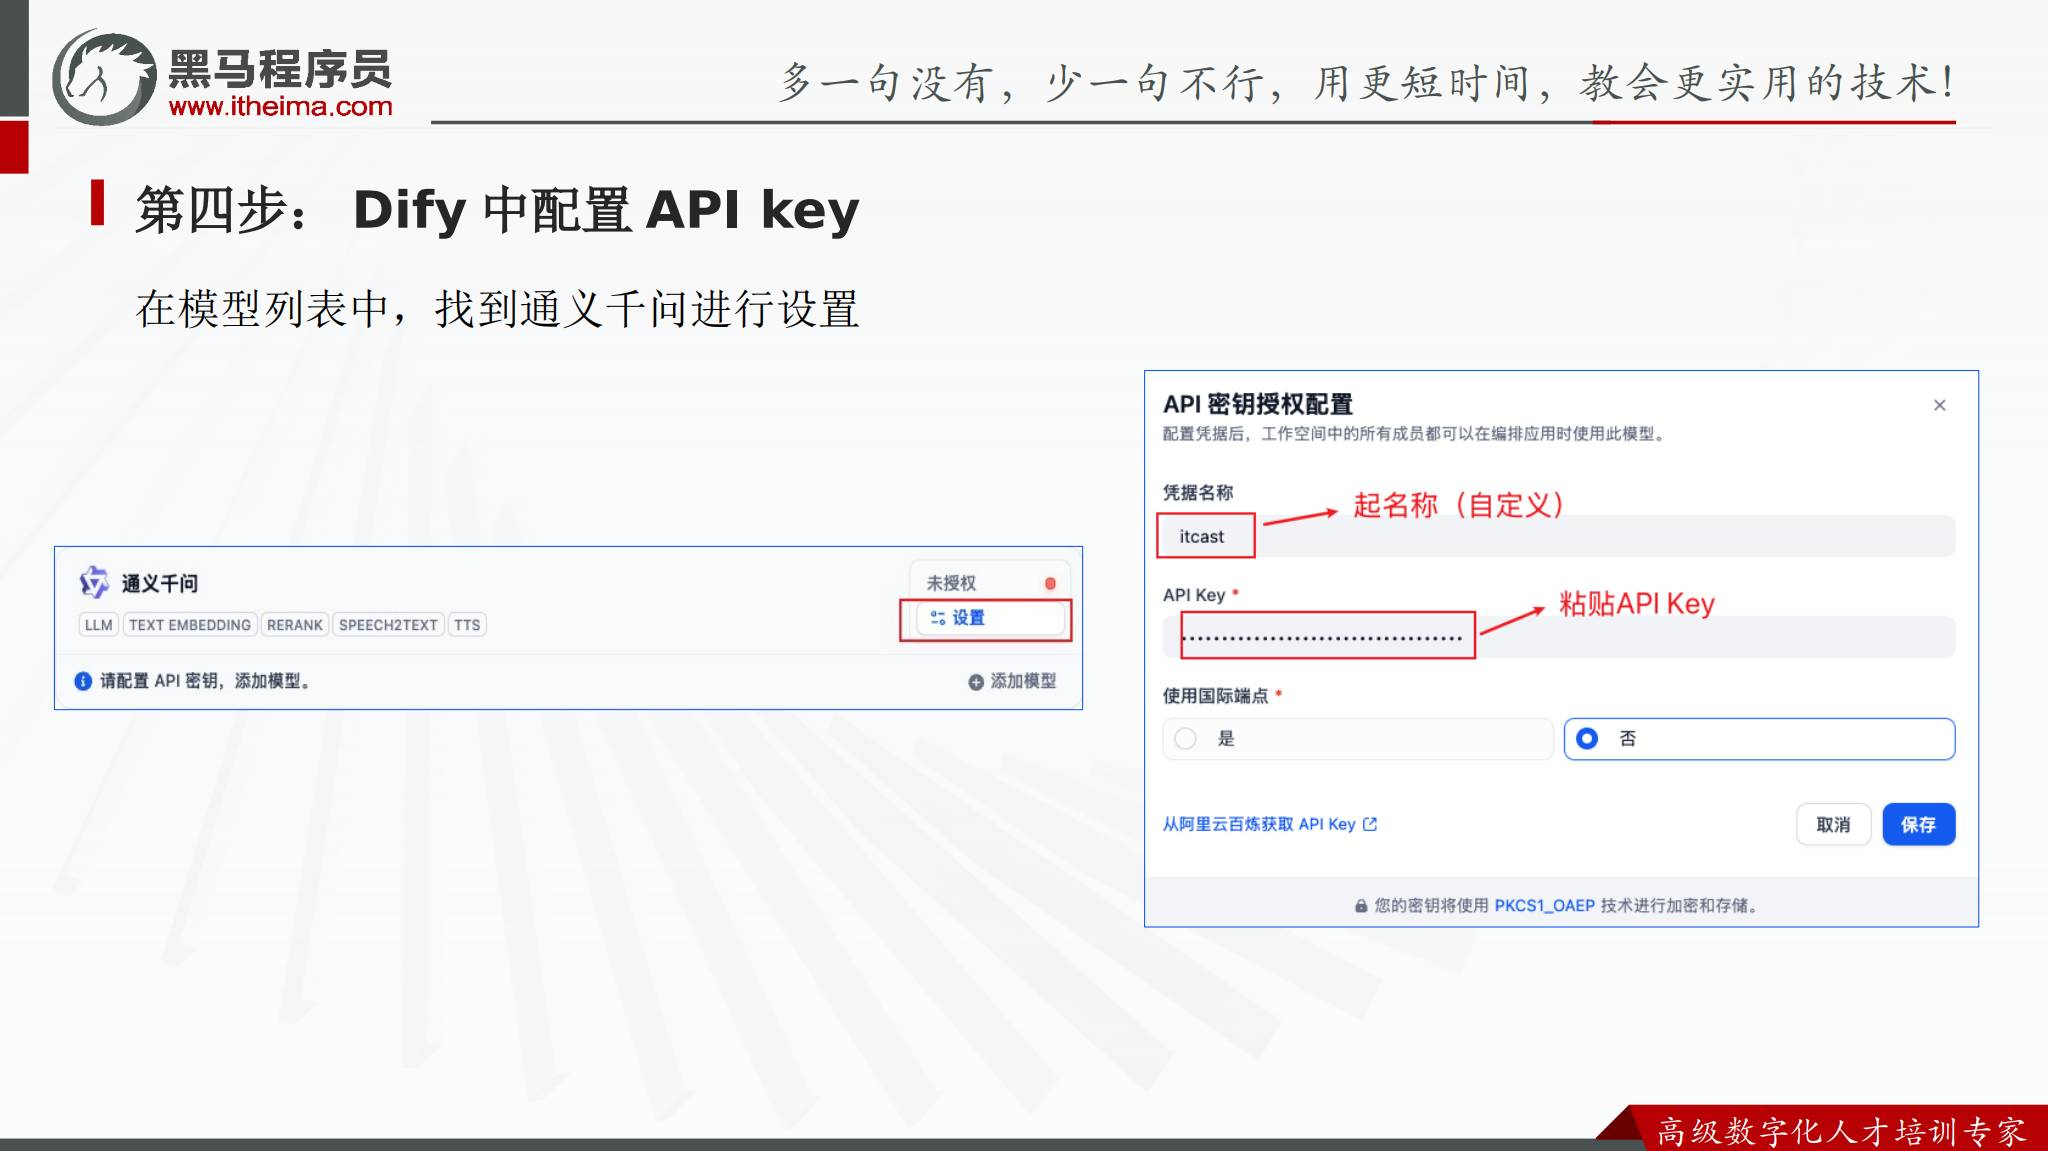

配置时要确认供应商、模型名称和 API Key 属于同一套云端服务。密钥配置完成后，不要把它复制到聊天记录、公开仓库或课程示例中。


## 14. 第五步：在 Dify 中测试 API 模型

配置完成后，在 Dify 应用中选择通义千问模型并发送测试消息。测试过程与本地模型类似，重点检查：

- Dify 是否识别到供应商和模型。
- API Key 是否有效。
- 账号是否满足平台的实名认证和调用条件。
- 请求是否成功返回模型结果。

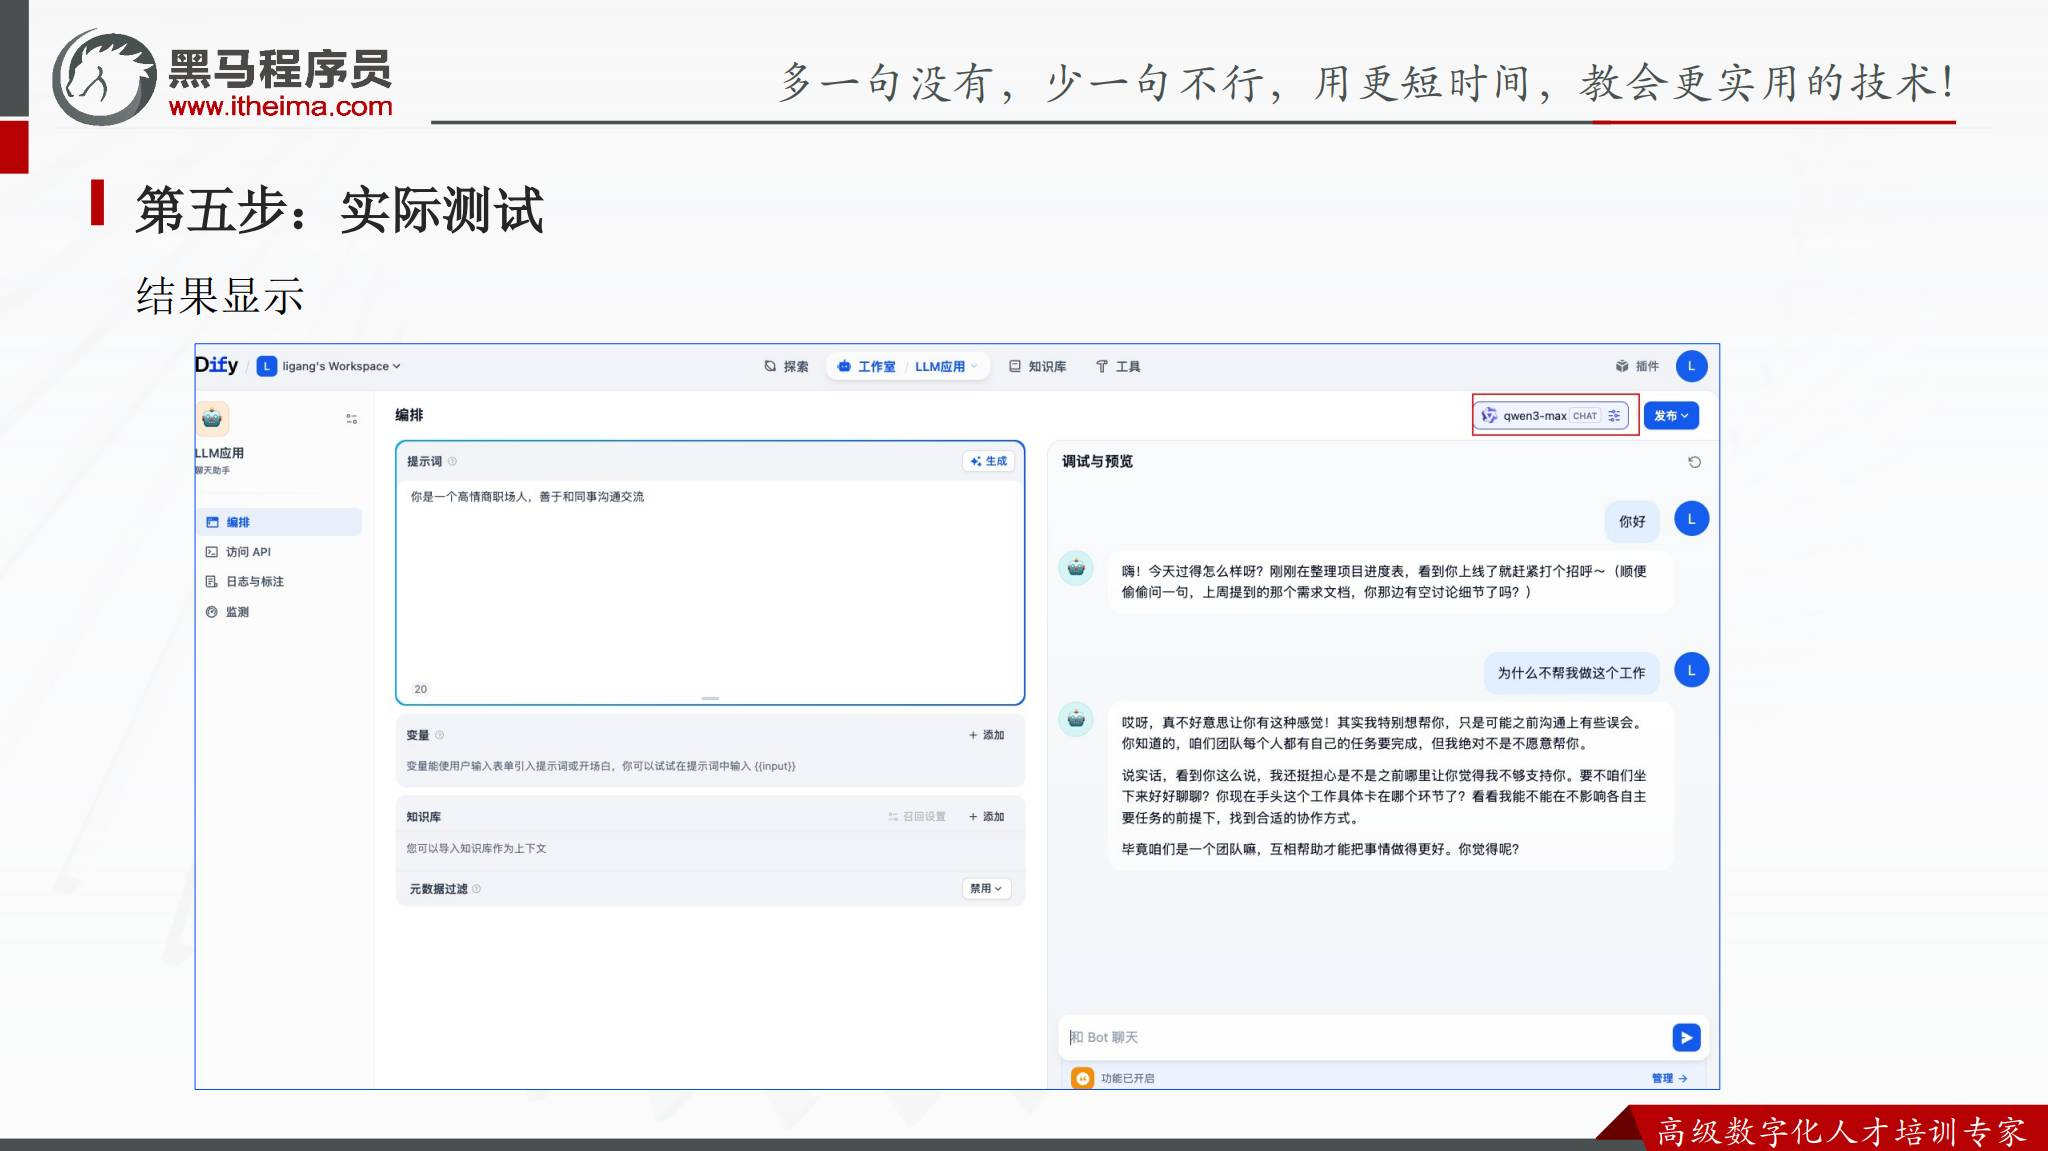


## 15. 两条接入路线的区别

| 对比项 | Ollama 本地模型 | API 大模型 |
| --- | --- | --- |
| 模型位置 | 本地电脑或局域网机器 | 云端服务 |
| 前置准备 | 安装 Ollama、下载模型 | 注册账号、实名认证、获取 API Key |
| Dify 配置 | 安装 Ollama 供应商，填写基础 URL | 安装对应云端供应商，填写 API Key |
| 运行成本 | 主要消耗本地硬件资源 | 按云端服务规则计费或使用额度 |
| 适合场景 | 本地学习、内网或数据不便外发的环境 | 快速使用云端模型能力 |

两条路线在 Dify 中的最后一步相同：配置供应商和模型，然后在应用里测试。


## 16. 本章小结

1. **什么是 Ollama？**

   Ollama 是本地大模型管理工具。接入 Dify 的顺序是：安装 Ollama、下载模型、运行模型、在 Dify 中配置 Ollama、测试模型。

2. **什么是大模型 API？**

   API 是远程调用云端大模型能力的接口，不需要自己部署和维护模型。接入 Dify 的顺序是：申请 API Key、安装对应供应商、添加模型配置、在应用中测试。

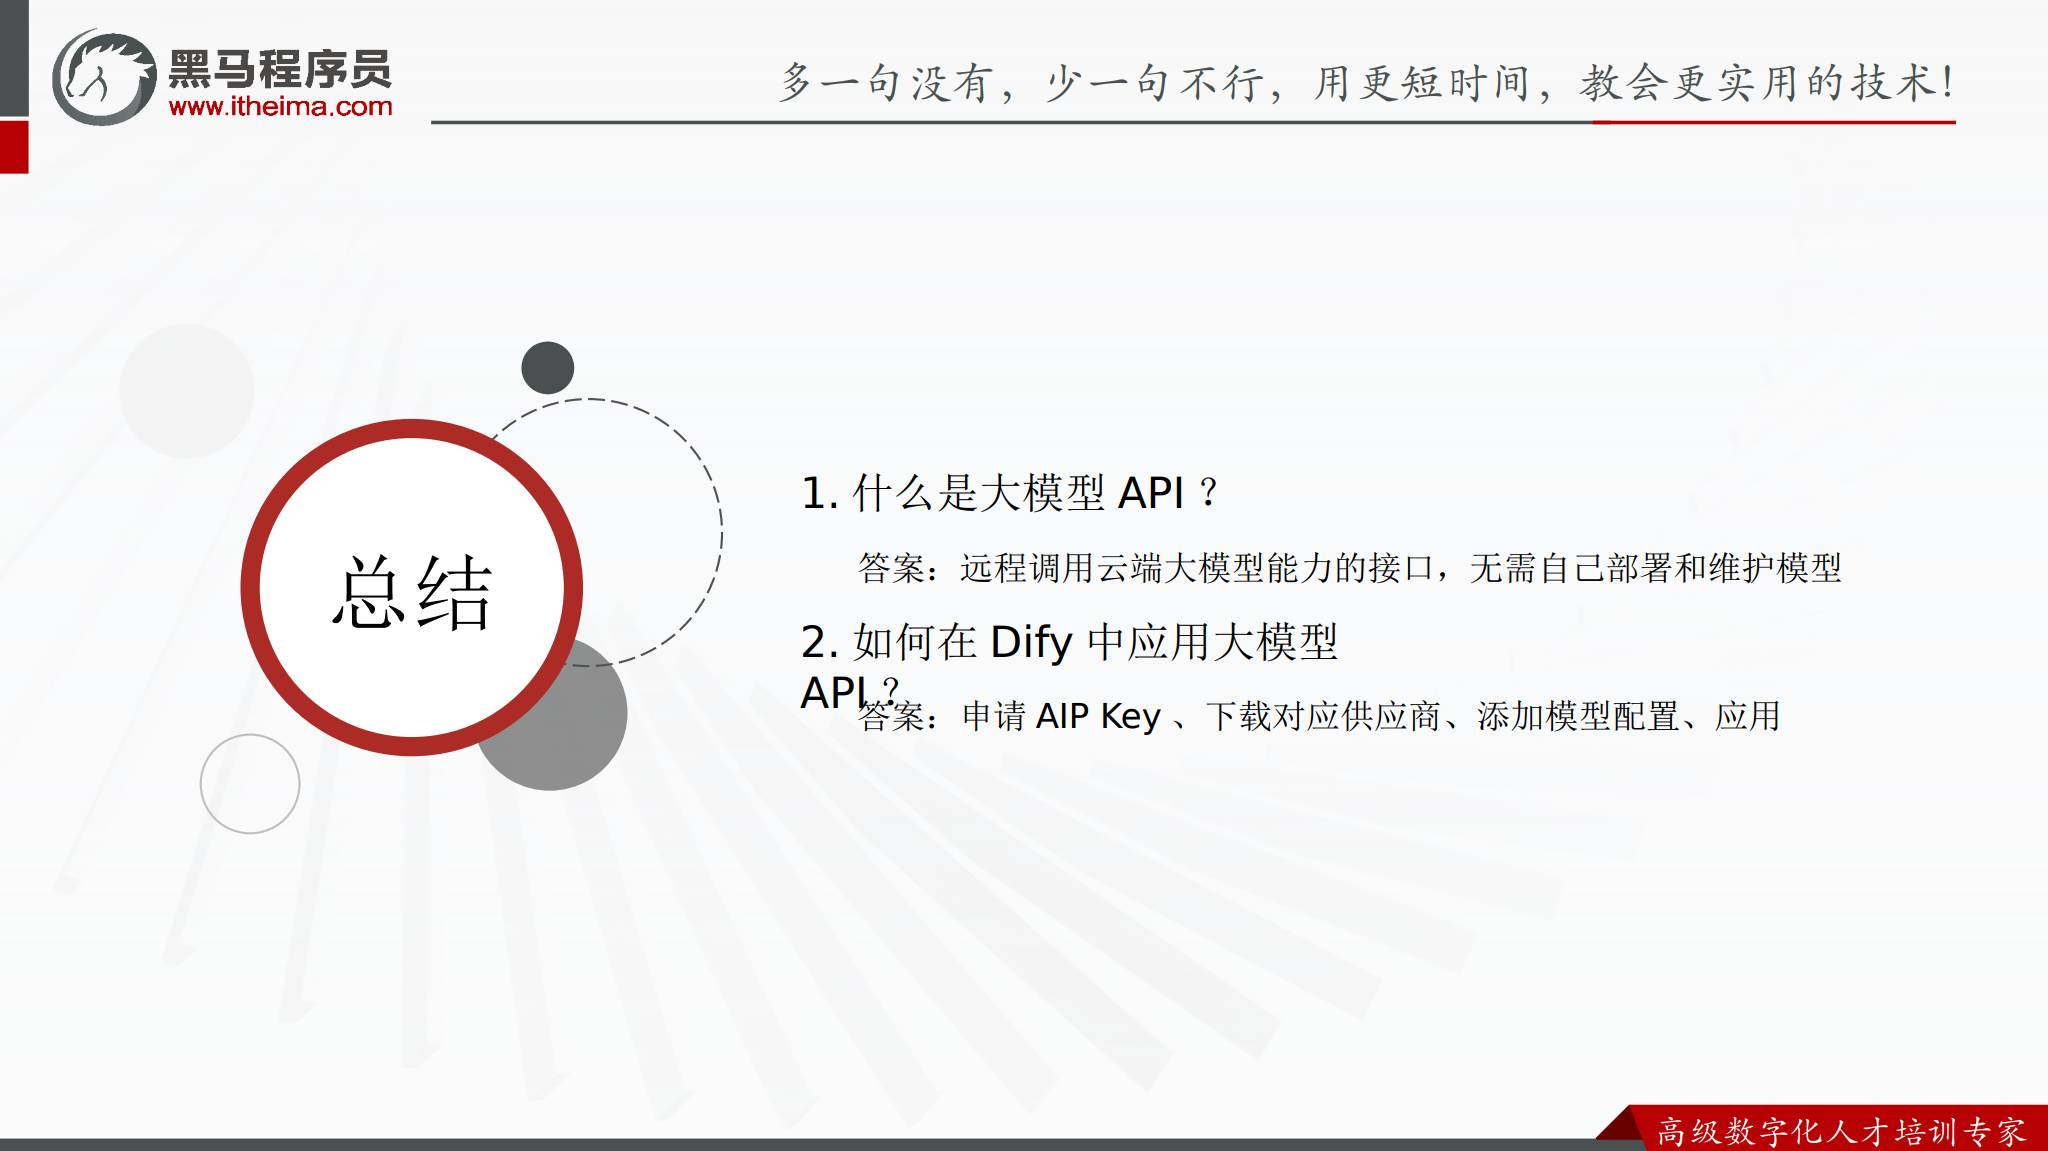


## 17. 资料边界

本篇依据第 2 章课件整理，覆盖 Ollama 本地模型和阿里云百炼 API 两条接入路线。课件展示了流程、示例模型、Ollama 基础 URL 和 API Key 配置位置；不同版本的 Ollama、Dify 或云平台界面可能存在差异，实际操作以当前页面和课程附件为准。
